In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Chebyshev
from numpy.polynomial import chebyshev as cheb
from scipy.optimize import least_squares
from scipy.stats import binom
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector
from itertools import product
import time
import heapq

In [2]:
# parameters

In [3]:
SEED = 20261015
ENSEMBLE_DRAWS = 256       
MSE_TRIALS = 40            
LAMBDA_CAL = 0.001         
CUBIC_PHASES = np.zeros(4)
SIGMA = 0.20               
RHO = 0.80
INTERVAL = 0.80
nodes, weights = np.polynomial.legendre.leggauss(64)
X_INT, W_INT = INTERVAL * nodes, INTERVAL * weights
X_PLOT = np.linspace(-INTERVAL, INTERVAL, 161)

In [4]:
plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 17,
    "legend.fontsize": 12.5,
    "lines.linewidth": 2.5,
    "figure.facecolor": "white",
})
np.set_printoptions(precision=8, suppress=True)
start_time = time.perf_counter()
print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.3.1


In [5]:
def hadamard_circuit(x, phases):
    circuit = QuantumCircuit(2)
    circuit.h(0)
    circuit.crz(-2 * phases[-1], 0, 1)
    for j in range(len(phases) - 2, -1, -1):
        circuit.crx(-2 * np.arccos(x), 0, 1)
        circuit.crz(-2 * phases[j], 0, 1)
    circuit.h(0)
    return circuit


def qiskit_response(x, phases):
    state = Statevector.from_instruction(hadamard_circuit(x, phases))
    probability_zero = state.probabilities([0])[0]
    return float(2 * probability_zero - 1)


def matrix_response(x, phases):
    x = np.atleast_1d(x).astype(float)
    sine = np.sqrt(np.maximum(0, 1 - x * x))
    row0 = np.full(x.shape, np.exp(1j * phases[0]), dtype=complex)
    row1 = np.zeros(x.shape, dtype=complex)
    for phase in phases[1:]:
        next0 = (x * row0 + 1j * sine * row1) * np.exp(1j * phase)
        next1 = (1j * sine * row0 + x * row1) * np.exp(-1j * phase)
        row0, row1 = next0, next1
    return row0.real


def covariance(degree, sigma, rho):
    locations = np.arange(degree + 1)
    return sigma**2 * rho ** np.abs(locations[:, None] - locations[None, :])


def path_data(phases):
    degree = len(phases) - 1
    signs = np.array([(1, *s, 1) for s in product((1, -1), repeat=degree - 1)])
    transitions = np.count_nonzero(signs[:, 1:] != signs[:, :-1], axis=1)
    return signs, transitions // 2, signs @ phases


def path_basis(x, degree, transitions):
    x = np.atleast_1d(x)
    k = transitions[:, None]
    return (-1.0)**k * x[None, :]**(degree - 2*k) * (1 - x[None, :]**2)**k


def exact_mean(x, phases, cov):
    signs, transitions, theta = path_data(phases)
    quadratic = np.sum((signs @ cov) * signs, axis=1)
    damping = np.exp(-quadratic / 2)
    basis = path_basis(x, len(phases) - 1, transitions)
    return (np.cos(theta) * damping) @ basis


def cubic_moments(x, phases, cov):
    assert len(phases) == 4
    signs, transitions, theta = path_data(phases)
    basis = path_basis(x, 3, transitions)
    mean = exact_mean(x, phases, cov)
    second = np.zeros_like(mean)
    for i, s in enumerate(signs):
        for j, u in enumerate(signs):
            difference, total = s - u, s + u
            kernel = 0.5 * (
                np.cos(theta[i] - theta[j]) * np.exp(-difference @ cov @ difference / 2)
                + np.cos(theta[i] + theta[j]) * np.exp(-total @ cov @ total / 2)
            )
            second += basis[i] * basis[j] * kernel
    variance = second - mean**2
    assert np.min(variance) > -1e-11
    return mean, second, np.maximum(variance, 0)


def best_scalar(g, mean, integration_weights):
    denominator = integration_weights @ (mean * mean)
    factor = (integration_weights @ (g * mean)) / denominator if denominator > 0 else 0
    floor = integration_weights @ ((factor * mean - g)**2)
    return float(factor), float(floor)


def estimate_response(x, phases, cov, draws, shots, rng):
    errors = rng.multivariate_normal(np.zeros(len(phases)), cov, size=draws)
    responses = np.array([qiskit_response(x, phases - e) for e in errors])
    if shots is not None:
        # Each binomial count is S measurements of ONE fixed error realization.
        probability = np.clip((1 + responses) / 2, 0, 1)
        responses = 2 * rng.binomial(shots, probability) / shots - 1
    return responses.mean(), responses.std(ddof=1) / np.sqrt(draws)


def estimate_curve(x, phases, cov, draws, rng, shots=None):
    values = [estimate_response(z, phases, cov, draws, shots, rng) for z in x]
    return np.array(values).T


def shared_noise_quadrature(x, phases, sigma, points=20):
    z, w = np.polynomial.hermite.hermgauss(points)
    values = []
    for point in np.atleast_1d(x):
        responses = [qiskit_response(point, phases - np.sqrt(2)*sigma*t)
                     for t in z]
        values.append(w @ responses / np.sqrt(np.pi))
    return np.array(values)


def finish_figure(fig, axes, filename):
    from matplotlib.container import ErrorbarContainer
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

    axes = np.asarray(axes).ravel()
    selected = filename in tuple(f'Fig{number}.png' for number in range(1, 9))
    blue, orange, green, purple = '#0072B2', '#D55E00', '#009E73', '#CC79A7'
    line_styles = ('-', '--', '-.', ':')
    markers = ('o', 's', '^', 'D')

    def set_curve(line, color, style, marker=None):
        line.set_color(color)
        line.set_linestyle(style)
        line.set_linewidth(2.5)
        if marker is not None:
            line.set_marker(marker)
            line.set_markersize(6.5)
            line.set_markerfacecolor('white')
            line.set_markeredgecolor(color)
            line.set_markeredgewidth(1.3)

    
    response_styles = {
        'Ideal response': ('black', ':'),
        'Target function': ('black', ':'),
        'Target inverse function': ('black', ':'),
        'Target': ('black', ':'),
        'Synthesized ideal polynomial': ('0.35', (0, (5, 1, 1, 1, 1, 1))),
        'Ideal polynomial': ('0.35', (0, (5, 1, 1, 1, 1, 1))),
        'Ideal approximation': ('0.35', (0, (5, 1, 1, 1, 1, 1))),
        'Noisy ensemble mean': (orange, '-'),
        'Noisy mean': (orange, '-'),
        'Noisy ensemble response': (orange, '-'),
        'Raw squared bias': (orange, '-'),
        'Independent-model correction': (blue, '--'),
        'Regularized calibration: expected mean': (green, '-.'),
        'Regularized calibration: including factor uncertainty': (green, '-.'),
        'Calibrated mean': (green, '-.'),
        'Best scalar (oracle)': (purple, (0, (2, 1))),
        'Exact factor mean': (green, '-.'),
        'Expected conditional squared bias': (green, '-.'),
        'Including calibration uncertainty': (green, '-.'),
        'Squared bias of expected response': (purple, '--'),
        'Calibrated; 512 calibration shots': (green, '-.'),
        'Raw; full budget for evaluation': (orange, '-'),
        'Infinite-calibration limit': ('black', ':'),
        'Uniform allocation': (orange, '-'),
        'Model-informed allocation': (green, '--'),
    }
    shorter_labels = {
        'Noisy ensemble mean': 'Noisy mean',
        'Noisy ensemble response': 'Noisy response',
        'Synthesized ideal polynomial': 'Ideal polynomial',
        'Regularized calibration: expected mean': 'Calibrated mean',
        'Regularized calibration: including factor uncertainty': 'Calibrated (factor uncertainty)',
        'Qiskit ensemble, +/-1 SE': 'Qiskit ensemble (±1 SE)',
        'Qiskit ensemble, ±1 SE': 'Qiskit ensemble (±1 SE)',
        'Corrected, one independent fit': 'Calibrated (one independent fit)',
        'Expected conditional squared bias': 'Expected conditional\nsquared bias',
        'Squared bias of expected response': 'Squared bias of mean response',
        'Including calibration uncertainty': 'Including factor uncertainty',
        'Calibrated; 512 calibration shots': 'Calibrated (512 calibration shots)',
        'Raw; full budget for evaluation': 'Raw (full evaluation budget)',
        'Endpoint-only control: maximum': 'Endpoint control (maximum)',
        'Qiskit quadrature, shared noise': 'Qiskit quadrature\n(shared noise)',
        'Endpoint-correlated: zero floor': 'Endpoint control (zero floor)',
    }
    for ax in axes:
        for line in ax.lines:
            if line.get_label() in response_styles:
                color, pattern = response_styles[line.get_label()]
                marker = line.get_marker()
                marker = None if marker in ('None', '', ' ') else marker
                set_curve(line, color, pattern, marker)
        for item in ax.containers:
            if not isinstance(item, ErrorbarContainer):
                continue
            name = item.get_label()
            if name.startswith(('Qiskit ensemble', 'Raw held-out')):
                color = orange
            elif name.startswith(('Corrected,', 'Factor mean')):
                color = green
            else:
                continue
            data_line, cap_lines, bar_lines = item.lines
            set_curve(data_line, color, data_line.get_linestyle(), data_line.get_marker())
            data_line.set_zorder(5)
            for cap in cap_lines:
                cap.set_color(color)
                cap.set_markersize(7)
                cap.set_markeredgewidth(1.2)
            for bars in bar_lines:
                bars.set_color(color)
                bars.set_linewidth(1.4)

    if filename == 'Fig1.png':
        for index, ax in enumerate(axes):
            panel = next(text for text in ax.texts if text.get_text().startswith(f'({chr(97 + index)})'))
            title = panel.get_text()
            panel.remove()
            ax.set_title(title, loc='left')

    elif filename == 'Fig3.png':
        for index, ax in enumerate(axes):
            panel = next(text for text in ax.texts if text.get_text().startswith(f'({chr(97 + index)})'))
            title = panel.get_text()
            panel.remove()
            if index < 3:
                ax.set_title(title + ' filter', loc='left')
            else:
                ax.set_title('(d) Integrated error', loc='left')
        axes[3].set_ylabel('Integrated squared error\nrelative to $f$')

    elif filename == 'Fig4.png':
        titles = [
            '(a) Transfer to held-out inputs', '(b) Calibration budget',
            '(c) Regularization', '(d) Factor versus location',
            '(e) Bias and factor uncertainty', '(f) MSE at 71,680 shots',
        ]
        for ax, title in zip(axes, titles):
            ax.set_title(title, loc='left')
        for ax in axes[3:]:
            ax.set_xlabel('Calibration magnitude $z$\nPair $(-z,+z)$')
        axes[5].set_ylabel('Integrated MSE')

    elif filename == 'Fig7.png':
        axes[0].set_ylabel('Calibrated MSE\n(evaluation grid)')
        axes[1].set_ylabel('Attenuation-estimate variance\n' + r'$\mathrm{Var}(\widehat a)$')

    elif filename == 'Fig8.png':
        for ax in axes[:2]:
            for line, pattern in zip(ax.lines[:4], line_styles):
                line.set_linestyle(pattern)
                line.set_linewidth(2.5)
       
        for index, box in enumerate(axes[2].patches):
            box.set_hatch('//' if index < len(axes[2].patches) // 2 else '..')
        axes[3].lines[0].set_linestyle('-')
        axes[3].lines[1].set_linestyle('--')
        for line in axes[3].lines:
            line.set_linewidth(2.5)
        for ax in axes[:3]:
            ax.set_ylabel('Normalized minimum bias\n' + r'$\mathcal{D}^{\star}_{\Sigma}/\|g\|_w^2$')
        axes[3].set_xlabel('Normalized minimum bias\n' + r'$\mathcal{D}^{\star}_{\Sigma}/\|g\|_w^2$')
        axes[3].set_ylabel('Empirical cumulative fraction')
        axes[2].set_title(rf'(c) Degree comparison, $\rho={RHO:g}$', loc='left')
        axes[3].set_title(rf'(d) Bias distribution, $d={check_degree}$', loc='left')
        for ax in axes:
            centered = ax.get_title(loc='center')
            ax.set_title('', loc='center')
            if not ax.get_title(loc='left'):
                ax.set_title(centered, loc='left')

    if filename == 'Fig2.png':
        for ax in axes:
            for line, color, style in zip(ax.lines[:3], (blue, orange, green), line_styles):
                set_curve(line, color, style)
            for annotation in list(ax.texts):
                if annotation.get_text() in ('(a)', '(b)'):
                    annotation.remove()
        set_curve(axes[1].lines[3], 'black', ':')
        set_curve(axes[1].lines[4], 'black', 'None', 'o')
        axes[1].lines[4].set_zorder(5)
        axes[0].set_title('(a) Correlation dependence', loc='left')
        axes[1].set_title('(b) Noise-strength dependence', loc='left')

    elif filename == 'Fig5.png':
        labels = ['Raw, full budget', 'Independent-model factor', 'Calibrated, calibration charged']
        for ax in axes:
            for line in ax.lines:
                if line.get_label() in labels:
                    index = labels.index(line.get_label())
                    marker = markers[index] if line.get_marker() not in ('None', '', ' ') else None
                    set_curve(line, (orange, blue, green)[index], line_styles[index], marker)

        errorbars = [item for item in axes[0].containers if isinstance(item, ErrorbarContainer)]
        for item, color, marker in zip(errorbars, (orange, blue, green), markers):
            data_line, cap_lines, bar_lines = item.lines
            set_curve(data_line, color, 'None', marker)
            data_line.set_zorder(5)
            for cap in cap_lines:
                cap.set_color(color)
                cap.set_markersize(8)
                cap.set_markeredgewidth(1.4)
            for bars in bar_lines:
                bars.set_color(color)
                bars.set_linewidth(1.5)

        titles = [
            '(a) Total measurement budget',
            '(b) Calibration allocation',
            '(c) Shots per phase-error realization',
        ]
        for ax, title in zip(axes, titles):
            ax.set_title(title, loc='left')
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        budgets = np.asarray(axes[0].lines[0].get_xdata())
        axes[0].set_xticks(budgets, labels=[f'{int(value):,}' for value in budgets])
        axes[0].xaxis.set_minor_formatter(NullFormatter())
        handles = [
            Line2D(
                [], [], color=color, linestyle=style, marker=marker,
                linewidth=2.5, markersize=6.5, markerfacecolor='white',
                markeredgewidth=1.3,
            )
            for color, style, marker in zip((orange, blue, green), line_styles, markers)
        ]
        for legend in list(fig.legends):
            legend.remove()
        fig.legend(
            handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.995),
            ncol=3, fontsize=12, frameon=False, handlelength=3.2, columnspacing=1.5,
        )

    elif filename == 'Fig6.png':
        curve_styles = {
            'Target inverse function': ('black', ':'),
            'Target': ('black', ':'),
            'Ideal polynomial': ('0.35', (0, (5, 1, 1, 1, 1, 1))),
            'Noisy mean': (orange, '-'),
            'Calibrated mean': (green, '-.'),
            'Ideal, finite shots': ('black', ':'),
            'Raw': (orange, '-'),
            'Independent-model factor': (blue, '--'),
            'Calibrated': (green, '-.'),
        }
        for ax in axes[:3]:
            for line in ax.lines:
                if line.get_label() in curve_styles:
                    color, style = curve_styles[line.get_label()]
                    set_curve(line, color, style)
        for line, marker in zip(axes[2].lines[:4], ('D', 'o', 's', '^')):
            set_curve(line, line.get_color(), line.get_linestyle(), marker)
        for line in axes[1].lines:
            if line.get_label() == 'Qiskit matrix quadrature':
                set_curve(line, orange, 'None', 'o')
                line.set_markersize(8)
                line.set_zorder(5)
        for line in axes[3].lines:
            raw = line.get_label().startswith('Raw,')
            set_curve(line, orange if raw else green, line.get_linestyle(), 'o' if raw else '^')
            line.set_markevery(3)
        for line, color, style, marker in zip(
            axes[4].lines[:4], (blue, orange, green, purple), line_styles, markers
        ):
            set_curve(line, color, style, marker)
        axes[4].lines[4].set_zorder(1.5)
        axes[4].yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        axes[4].yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'))
        axes[4].yaxis.set_minor_formatter(NullFormatter())
        for other_ax in fig.axes:
            if other_ax not in axes:
                other_ax.yaxis.label.set_fontsize(15)
                other_ax.tick_params(labelsize=12)
                other_ax.yaxis.get_offset_text().set_fontsize(12)

    for ax in axes:
        if selected:
            ax.xaxis.label.set_size(17)
            ax.yaxis.label.set_size(17)
            ax.xaxis.labelpad = 9
            ax.yaxis.labelpad = 9
            ax.tick_params(axis='both', which='both', labelsize=14)
            ax.tick_params(axis='both', which='major', length=5, width=1.0)
            ax.xaxis.get_offset_text().set_fontsize(12)
            ax.yaxis.get_offset_text().set_fontsize(12)
            for location in ('left', 'center', 'right'):
                title = ax.get_title(loc=location)
                if title:
                    ax.set_title(title, loc=location, fontsize=15, pad=12)
            for annotation in ax.texts:
                annotation.set_fontsize(12)
                annotation.set_text(annotation.get_text().replace('+/-', '±').replace('25--75%', '25–75%'))
            if filename != 'Fig5.png' and ax.get_legend() is not None:
                handles, names = ax.get_legend_handles_labels()
                names = [shorter_labels.get(name, name).replace('+/-', '±') for name in names]
                ax.legend(
                    handles, names, loc='best', fontsize=12.5,
                    frameon=True, framealpha=0.95, facecolor='white',
                    edgecolor='0.85', handlelength=3.1,
                    labelspacing=0.45, borderpad=0.6,
                )
        ax.set_axisbelow(True)
        ax.grid(True, alpha=0.18 if selected else 0.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    if filename in ('Fig1.png', 'Fig3.png', 'Fig7.png'):
        response_axes = axes[:3] if filename == 'Fig3.png' else axes
        legend_items = {}
        for ax in response_axes:
            handles, names = ax.get_legend_handles_labels()
            for handle, name in zip(handles, names):
                name = shorter_labels.get(name, name)
                if name not in legend_items:
                    legend_items[name] = handle
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        for legend in list(fig.legends):
            legend.remove()
        if filename == 'Fig3.png':
            names = [name.replace('Independent-model correction', 'Independent-model\ncorrection')
                     .replace('Qiskit ensemble (±1 SE)', 'Qiskit ensemble\n(±1 SE)')
                     for name in legend_items]
            axes[2].legend(
                list(legend_items.values()), names,
                loc='upper center', bbox_to_anchor=(0.5, -0.27),
                ncol=2, fontsize=12, frameon=False, handlelength=3.0,
                columnspacing=1.2, labelspacing=0.7,
            )
        else:
            fig.legend(
                list(legend_items.values()), list(legend_items),
                loc='lower center', bbox_to_anchor=(0.5, 0.015),
                ncol=3 if filename != 'Fig7.png' else 2,
                fontsize=12.5, frameon=False, handlelength=3.1,
                columnspacing=1.4, labelspacing=0.8,
            )
    if filename == 'Fig8.png':
        handles, names = axes[0].get_legend_handles_labels()
        names = [shorter_labels.get(name, name) for name in names]
        for ax in axes[:2]:
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        fig.legend(
            handles, names, loc='upper center', bbox_to_anchor=(0.5, 0.995),
            ncol=5, fontsize=12, frameon=False, handlelength=3.0,
            columnspacing=1.4,
        )
        handles, names = axes[2].get_legend_handles_labels()
        axes[2].legend(
            handles, names, loc='upper left', ncol=2, fontsize=12,
            frameon=True, framealpha=0.95, edgecolor='0.85',
            columnspacing=0.7, handletextpad=0.4,
        )

    if filename == 'Fig6.png':
        axes[3].legend(
            loc='upper center', bbox_to_anchor=(0.5, -0.29), ncol=2,
            fontsize=11.5, frameon=False, handlelength=3.1, columnspacing=1.1,
        )


    if filename == 'Fig3.png':
        handles, names = axes[3].get_legend_handles_labels()
        names = [
            'Ideal approximation', 'Noisy response',
            'Independent-model\ncorrection', 'Calibrated\n(factor uncertainty)',
        ]
        axes[3].legend(
            handles, names, loc='upper center', bbox_to_anchor=(0.5, -0.27),
            ncol=2, fontsize=12, frameon=False, handlelength=3.0,
            columnspacing=1.2, labelspacing=0.7,
        )
    elif filename == 'Fig4.png':
        handles, names = axes[0].get_legend_handles_labels()
        names = [shorter_labels.get(name, name) for name in names]
        names = [name.replace('Calibrated (one independent fit)',
                              'Calibrated\n(one independent fit)') for name in names]
        axes[0].legend(
            handles, names, loc='upper center', bbox_to_anchor=(0.5, -0.30),
            ncol=2, fontsize=12, frameon=False, handlelength=3.0,
            columnspacing=1.2, labelspacing=0.6,
        )
    elif filename == 'Fig6.png':
        handles, names = axes[0].get_legend_handles_labels()
        names = [name.replace('Target inverse function', 'Target function') for name in names]
        axes[0].legend(
            handles, names, loc='upper center', bbox_to_anchor=(0.5, -0.29),
            ncol=2, fontsize=12, frameon=False, handlelength=3.0,
            columnspacing=1.2, labelspacing=0.6,
        )

    if filename in ('Fig1.png', 'Fig7.png'):
        bottom = 0.14 if filename == 'Fig1.png' else 0.10
        fig.tight_layout(rect=(0, bottom, 1, 1), pad=1.5, w_pad=3.0, h_pad=3.2)
    elif filename == 'Fig5.png':
        fig.tight_layout(rect=(0, 0, 1, 0.94), pad=1.5, w_pad=3.0, h_pad=3.5)
    elif filename == 'Fig8.png':
        fig.tight_layout(rect=(0, 0, 1, 0.95), pad=1.5, w_pad=3.0, h_pad=3.5)
    elif selected:
        fig.tight_layout(pad=1.5, w_pad=3.0, h_pad=3.5)
    else:
        fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved', filename, flush=True)



In [6]:
check_rng = np.random.default_rng(SEED)
check_phases = check_rng.normal(size=6)
check_error = max(abs(qiskit_response(x, check_phases)
                      - matrix_response(x, check_phases)[0])
                  for x in (-1, -0.7, 0, 0.37, 1))
assert check_error < 1e-10
print("Signed-circuit maximum error:", check_error)

Signed-circuit maximum error: 1.2212453270876722e-15


Fig1 correlated case: oracle factor = 1.0196949745006578 bias floor = 0.0009959164406195607


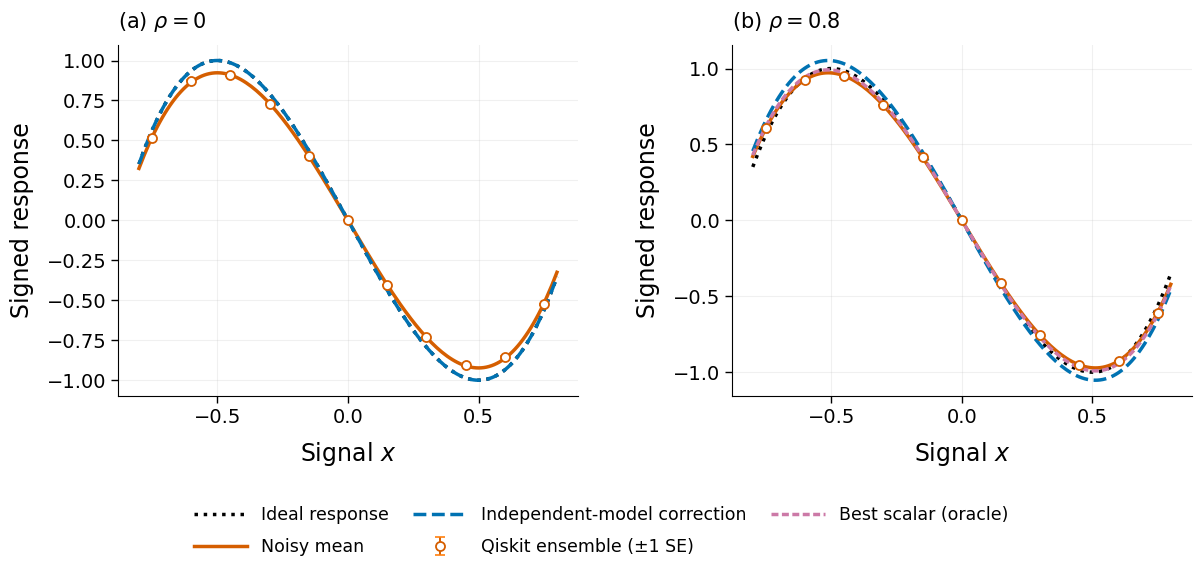

Saved Fig1.png


In [7]:
rng = np.random.default_rng(SEED + 1)
fig, axes = plt.subplots(1, 2, figsize=(12.4, 6.0))
g = matrix_response(X_PLOT, CUBIC_PHASES)
g_int = matrix_response(X_INT, CUBIC_PHASES)
marker_x = np.linspace(-0.75, 0.75, 11)
for ax, rho, panel in zip(axes, (0.0, RHO), ("a", "b")):
    cov = covariance(3, SIGMA, rho)
    mean = exact_mean(X_PLOT, CUBIC_PHASES, cov)
    independent_factor = np.exp(np.trace(cov) / 2)
    ax.plot(X_PLOT, g, "k-", label="Ideal response")
    ax.plot(X_PLOT, mean, color="tab:orange", label="Noisy ensemble mean")
    ax.plot(X_PLOT, independent_factor * mean, "--", color="tab:green",
            label="Independent-model correction")
    if rho > 0:
        oracle, floor = best_scalar(g_int, exact_mean(X_INT, CUBIC_PHASES, cov), W_INT)
        ax.plot(X_PLOT, oracle * mean, ":", color="tab:purple", label="Best scalar (oracle)")
        print("Fig1 correlated case: oracle factor =", oracle, "bias floor =", floor)
    sampled, se = estimate_curve(marker_x, CUBIC_PHASES, cov, ENSEMBLE_DRAWS, rng)
    ax.errorbar(marker_x, sampled, yerr=se, fmt="o", ms=3, color="tab:orange",
                capsize=2, label="Qiskit ensemble, ±1 SE")
    ax.text(0.03, 0.96, rf"({panel}) $\rho={rho:g}$", transform=ax.transAxes, va="top")
    ax.set_xlabel(r"Signal $x$")
    ax.set_ylabel(r"Signed response")
    ax.legend(loc="lower left")
finish_figure(fig, axes, "Fig1.png")

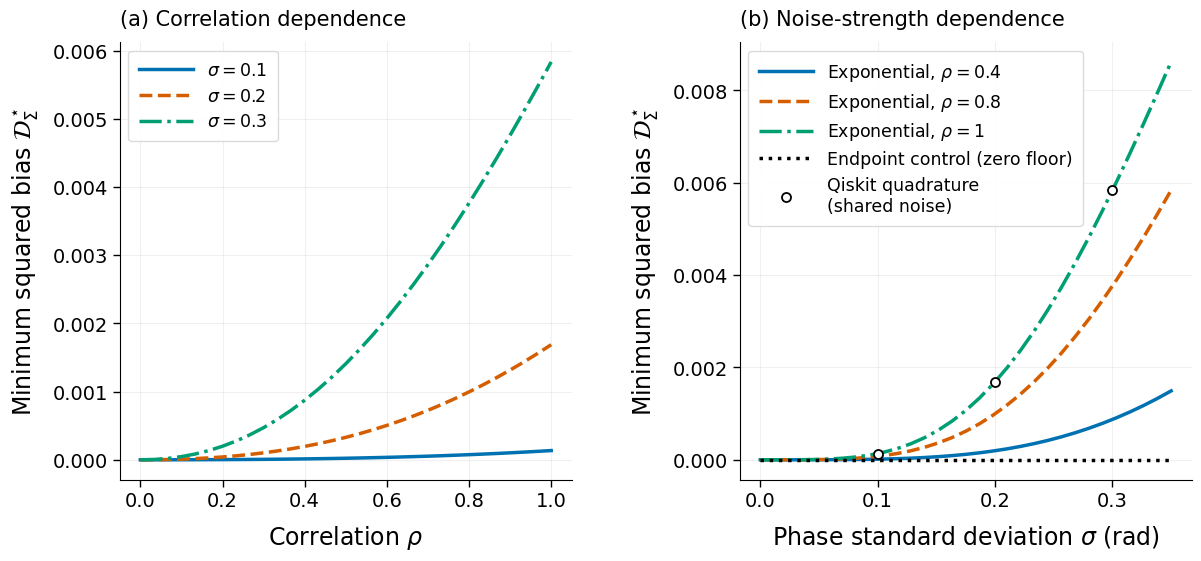

Saved Fig2.png


In [8]:
g_int = matrix_response(X_INT, CUBIC_PHASES)
fig, axes = plt.subplots(1, 2, figsize=(12.4, 6.0))
for sigma in (0.10, 0.20, 0.30):
    rhos = np.linspace(0, 1, 31)
    floors = []
    for rho in rhos:
        mean = exact_mean(X_INT, CUBIC_PHASES, covariance(3, sigma, rho))
        floors.append(best_scalar(g_int, mean, W_INT)[1] if rho > 0 else 0.0)
    axes[0].plot(rhos, floors, label=rf"$\sigma={sigma:g}$")
axes[0].set_xlabel(r"Correlation $\rho$")
axes[0].set_ylabel(r"Minimum squared bias $\mathcal{D}_\Sigma^\star$")
axes[0].legend()
axes[0].text(0.03, 0.96, "(a)", transform=axes[0].transAxes, va="top")

sigmas = np.linspace(0, 0.35, 31)
for rho in (0.4, 0.8, 1.0):
    floors = [best_scalar(g_int, exact_mean(X_INT, CUBIC_PHASES,
              covariance(3, s, rho)), W_INT)[1] for s in sigmas]
    axes[1].plot(sigmas, floors, label=rf"Exponential, $\rho={rho:g}$")

recoverable_floors = []
for sigma in sigmas:
    cov = sigma**2 * np.eye(4)
    cov[0, 3] = cov[3, 0] = 0.8 * sigma**2
    mean = exact_mean(X_INT, CUBIC_PHASES, cov)
    recoverable_floors.append(best_scalar(g_int, mean, W_INT)[1])
assert max(recoverable_floors) < 1e-20
axes[1].plot(sigmas, np.zeros_like(sigmas), "k--", label="Endpoint-correlated: zero floor")

qx, qw = np.polynomial.legendre.leggauss(7)
qx, qw = INTERVAL*qx, INTERVAL*qw
check_sigmas = np.array([0.10, 0.20, 0.30])
qiskit_floors = []
for sigma in check_sigmas:
    mean_q = shared_noise_quadrature(qx, CUBIC_PHASES, sigma)
    theory_q = exact_mean(qx, CUBIC_PHASES, covariance(3, sigma, 1.0))
    assert np.max(abs(mean_q - theory_q)) < 1e-9
    qiskit_floors.append(best_scalar(matrix_response(qx, CUBIC_PHASES), mean_q, qw)[1])
axes[1].plot(check_sigmas, qiskit_floors, "ko", ms=4, label="Qiskit quadrature, shared noise")
axes[1].set_xlabel(r"Phase standard deviation $\sigma$ (rad)")
axes[1].set_ylabel(r"Minimum squared bias $\mathcal{D}_\Sigma^\star$")
axes[1].legend(loc="upper left")
axes[1].text(0.95, 0.96, "(b)", transform=axes[1].transAxes, va="top", ha="right")
finish_figure(fig, axes, "Fig2.png")

In [9]:
def synthesize_phases(polynomial):
    degree = polynomial.degree()
    assert degree % 2 == 1
    roots = polynomial.deriv().roots()
    real_roots = roots[np.abs(roots.imag) < 1e-9].real
    real_roots = real_roots[np.abs(real_roots) <= 1]
    extrema = np.r_[-1, real_roots, 1]
    assert np.max(abs(polynomial(extrema))) < 1
    fit_x = np.cos(np.pi*(np.arange(degree + 3) + 0.5)/(degree + 3))
    initial = np.zeros((degree + 1)//2)
    initial[0] = np.pi/4
    def residual(theta):
        phases = np.r_[theta, theta[::-1]]
        return matrix_response(fit_x, phases) - polynomial(fit_x)
    solution = least_squares(residual, initial, max_nfev=1500,
                             xtol=1e-12, ftol=1e-12, gtol=1e-12)
    phases = np.r_[solution.x, solution.x[::-1]]
    dense_x = np.linspace(-1, 1, 1001)
    fit_error = np.max(abs(matrix_response(dense_x, phases) - polynomial(dense_x)))
    circuit_error = max(abs(qiskit_response(x, phases) - polynomial(x))
                        for x in (-1, -0.73, 0.19, 0.64, 1))
    assert fit_error < 1e-7 and circuit_error < 1e-7
    print(f"Degree {degree}: synthesis error {fit_error:.2e}; phases = {phases}")
    return phases


def calibration_moments(n_cal, g_plus, m_plus, regularization):
    assert n_cal > 0 and n_cal % 2 == 0 and abs(g_plus) > 1e-8
    k = np.arange(n_cal + 1)
    probability = (1 + np.sign(g_plus)*m_plus)/2
    probabilities = binom.pmf(k, n_cal, probability)
    probabilities /= probabilities.sum()
    a_values = (2*k/n_cal - 1)/abs(g_plus)
    b_values = a_values/(a_values*a_values + regularization)
    mean_b = probabilities @ b_values
    variance_b = probabilities @ ((b_values - mean_b)**2)
    return float(mean_b), float(variance_b)

def sample_calibration(phases, cov, z, n_cal, regularization, rng):
    cal_x = np.array([-z, z])
    cal_g = matrix_response(cal_x, phases)
    measured = [estimate_response(x, phases, cov, n_cal//2, 1, rng)[0]
                for x in cal_x]
    a_hat = cal_g @ measured / (cal_g @ cal_g)
    return float(a_hat/(a_hat*a_hat + regularization))


def exact_second_moment(x, phases, cov, block_size=128):
    signs, transitions, theta = path_data(phases)
    degree = len(phases) - 1
    groups = degree // 2 + 1
    quadratic = np.sum((signs @ cov) * signs, axis=1)
    membership = np.zeros((len(signs), groups))
    membership[np.arange(len(signs)), transitions] = (-1.0)**transitions
    grouped_kernel = np.zeros((groups, groups))
    for first in range(0, len(signs), block_size):
        last = min(first + block_size, len(signs))
        cross = (signs[first:last] @ cov) @ signs.T
        half_sum = (quadratic[first:last, None] + quadratic[None, :]) / 2
        difference = theta[first:last, None] - theta[None, :]
        total = theta[first:last, None] + theta[None, :]
        kernel = 0.5 * (
            np.cos(difference) * np.exp(-half_sum + cross)
            + np.cos(total) * np.exp(-half_sum - cross)
        )
        grouped_kernel += membership[first:last].T @ kernel @ membership
    x = np.atleast_1d(x)
    k = np.arange(groups)[:, None]
    basis = x[None, :]**(degree-2*k) * (1-x[None, :]**2)**k
    return np.einsum('ki,kl,li->i', basis, grouped_kernel, basis)

Degree 5: synthesis error 8.88e-16; phases = [ 0.70797412  0.15643382 -0.57514252 -0.57514252  0.15643382  0.70797412]
Fig3 degree 5: mean factor=1.01957105, SD=0.03882532, calibrated ensemble error=2.476781046e-03
Degree 9: synthesis error 7.77e-16; phases = [ 0.7751874   0.01939924 -0.0517113   0.1498077  -0.57223629 -0.57223629
  0.1498077  -0.0517113   0.01939924  0.7751874 ]
Fig3 degree 9: mean factor=1.03760518, SD=0.04777930, calibrated ensemble error=1.401198130e-03
Degree 13: synthesis error 1.22e-15; phases = [ 0.78402937  0.00259309 -0.00682709  0.01868422 -0.05170069  0.14986792
 -0.57222563 -0.57222563  0.14986792 -0.05170069  0.01868422 -0.00682709
  0.00259309  0.78402937]
Fig3 degree 13: mean factor=1.04292221, SD=0.04812603, calibrated ensemble error=1.455240611e-03


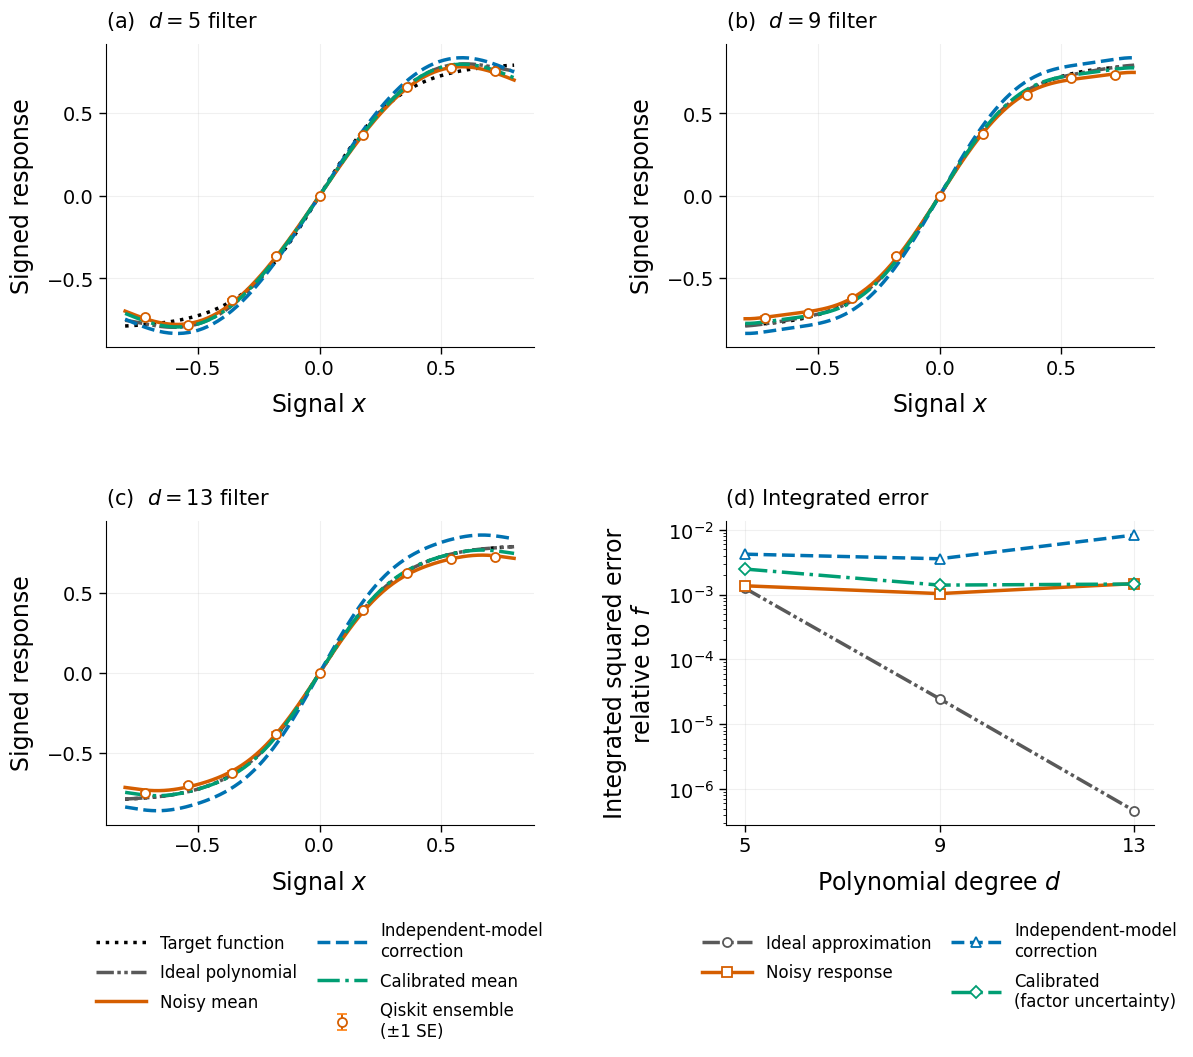

Saved Fig3.png

Higher-degree table: d, total shots, calibration shots, raw MSE, independent-model MSE, calibrated MSE (relative to f)
5 2560 512 2.877257628e-02 3.557115499e-02 3.814008664e-02
Same comparison relative to ideal polynomial g: 2.801507761e-02 3.249765040e-02 3.673349028e-02
MSE reduction relative to f: -32.56%
MSE reduction relative to g: -31.12%
5 71680 14336 2.345262785e-03 5.324122584e-03 2.840084576e-03
Same comparison relative to ideal polynomial g: 1.587764109e-03 2.250617994e-03 1.480279737e-03
MSE reduction relative to f: -21.10%
MSE reduction relative to g: 6.77%
9 2560 512 3.064523387e-02 4.065255986e-02 4.133330688e-02
Same comparison relative to ideal polynomial g: 3.060361346e-02 4.057306459e-02 4.127972490e-02
MSE reduction relative to f: -34.88%
MSE reduction relative to g: -34.89%
9 71680 14336 2.093413201e-03 4.896466256e-03 1.598149044e-03
Same comparison relative to ideal polynomial g: 2.051792792e-03 4.816970986e-03 1.545233098e-03
MSE reduction relat

In [10]:
rng = np.random.default_rng(SEED + 3)
filter_function = lambda x: 0.8 * np.tanh(3*x)
degrees = (5, 9, 13)
filter_sigma, filter_rho = 0.15, 0.80
filter_cal_z = 0.5
filter_cal_shots = 512
filter_shots_per_realization = 8
filter_total_budgets = (2560, 71680)
assert np.all(np.abs(np.abs(X_INT) - filter_cal_z) > 1e-12)
fig, axes = plt.subplots(2, 2, figsize=(12.4, 11.2))
approximation_errors, raw_errors, corrected_errors = [], [], []
calibrated_errors = []
filter_budget_rows = []

for panel, (ax, degree) in enumerate(zip(axes.ravel()[:3], degrees)):
    coefficients = cheb.chebinterpolate(filter_function, degree)
    coefficients[::2] = 0
    polynomial = Chebyshev(coefficients)
    phases = synthesize_phases(polynomial)
    cov = covariance(degree, filter_sigma, filter_rho)
    mean = exact_mean(X_PLOT, phases, cov)
    b0 = np.exp(np.trace(cov)/2)
    g_cal = float(polynomial(filter_cal_z))
    m_cal = float(exact_mean(filter_cal_z, phases, cov)[0])
    b_mean, b_var = calibration_moments(
        filter_cal_shots, g_cal, m_cal, LAMBDA_CAL)

    ax.plot(X_PLOT, filter_function(X_PLOT), 'k:', label='Target function')
    ax.plot(X_PLOT, polynomial(X_PLOT), color='tab:blue',
            label='Synthesized ideal polynomial')
    ax.plot(X_PLOT, mean, color='tab:orange', label='Noisy mean')
    ax.plot(X_PLOT, b0*mean, '--', color='tab:green',
            label='Independent-model correction')
    ax.plot(X_PLOT, b_mean*mean, '-.', color='tab:purple',
            label='Regularized calibration: expected mean')
    marker_x = np.linspace(-0.72, 0.72, 9)
    sampled, se = estimate_curve(marker_x, phases, cov, ENSEMBLE_DRAWS, rng)
    ax.errorbar(marker_x, sampled, yerr=se, fmt='o', ms=3,
                color='tab:orange', capsize=2, label='Qiskit ensemble, +/-1 SE')
    ax.text(0.03, 0.96, f'({chr(97+panel)})  $d={degree}$',
            transform=ax.transAxes, va='top')
    ax.set_xlabel(r'Signal $x$')
    ax.set_ylabel('Signed response')
    ax.legend(loc='lower right', fontsize=8)

    mean_int = exact_mean(X_INT, phases, cov)
    ideal_int = polynomial(X_INT)
    target_int = filter_function(X_INT)
    approximation_errors.append(W_INT @ ((ideal_int-target_int)**2))
    raw_errors.append(W_INT @ ((mean_int-target_int)**2))
    corrected_errors.append(W_INT @ ((b0*mean_int-target_int)**2))
    calibrated_errors.append(W_INT @ (
        (b_mean*mean_int-target_int)**2 + b_var*mean_int**2))
    print(f'Fig3 degree {degree}: mean factor={b_mean:.8f}, '
          f'SD={np.sqrt(b_var):.8f}, '
          f'calibrated ensemble error={calibrated_errors[-1]:.9e}')
    second_int = exact_second_moment(X_INT, phases, cov)
    response_variance = second_int - mean_int**2
    assert response_variance.min() > -1e-9
    response_variance = np.maximum(response_variance, 0)
    q_filter = len(X_INT)
    sampling_numerator = (
        1-mean_int**2
        + (filter_shots_per_realization-1)*response_variance)
    for n_total_filter in filter_total_budgets:
        n_cal_filter = n_total_filter//5
        n_eval_filter = n_total_filter-n_cal_filter
        assert n_total_filter % (q_filter*filter_shots_per_realization) == 0
        assert n_eval_filter % (q_filter*filter_shots_per_realization) == 0
        v_raw = sampling_numerator/(n_total_filter//q_filter)
        v_eval = sampling_numerator/(n_eval_filter//q_filter)
        bm, bv = calibration_moments(
            n_cal_filter, g_cal, m_cal, LAMBDA_CAL)
        risks_by_reference = []
        for reference in (target_int, ideal_int):
            risk_raw = W_INT @ ((mean_int-reference)**2 + v_raw)
            risk_independent = W_INT @ (
                (b0*mean_int-reference)**2 + b0**2*v_raw)
            risk_calibrated = W_INT @ (
                (bm*mean_int-reference)**2 + bm**2*v_eval
                + bv*(mean_int**2+v_eval))
            risks_by_reference.append(
                (risk_raw, risk_independent, risk_calibrated))
        filter_budget_rows.append(
            (degree, n_total_filter, n_cal_filter, *risks_by_reference))

ax = axes[1, 1]
ax.semilogy(degrees, approximation_errors, 'o-', color='tab:blue',
            label='Ideal approximation')
ax.semilogy(degrees, raw_errors, 's-', color='tab:orange',
            label='Noisy ensemble response')
ax.semilogy(degrees, corrected_errors, '^--', color='tab:green',
            label='Independent-model correction')
ax.semilogy(degrees, calibrated_errors, 'D-', color='tab:purple',
            label='Regularized calibration: including factor uncertainty')
ax.text(0.03, 0.96, r'(d)  $N_{\mathrm{cal}}=512$',
        transform=ax.transAxes, va='top')
ax.set_xlabel(r'Polynomial degree $d$')
ax.set_ylabel(r'Integrated squared error relative to $f$')
ax.set_xticks(degrees)
ax.legend(loc='lower left', fontsize=7.8)
finish_figure(fig, axes, 'Fig3.png')

print("\nHigher-degree table: d, total shots, calibration shots, raw MSE, "
"independent-model MSE, calibrated MSE (relative to f)")
for degree, n_total_filter, n_cal_filter, risks_f, risks_g in filter_budget_rows:
    print(degree, n_total_filter, n_cal_filter, *[f'{risk:.9e}' for risk in risks_f])
    print('Same comparison relative to ideal polynomial g:', *[f'{risk:.9e}' for risk in risks_g])
    print(f'MSE reduction relative to f: {100*(risks_f[0]-risks_f[2])/risks_f[0]:.2f}%')
    print(f'MSE reduction relative to g: {100*(risks_g[0]-risks_g[2])/risks_g[0]:.2f}%')

Fig4 original fit: b_hat = 1.027026867. Panel (a) bars condition on this fit; factor bands and bars show SD, not confidence intervals.
Fig4 location comparison: sigma = 0.2, rho = 0.8, lambda_cal = 0.001, calibration shots = 512, total shots = 71680, evaluation shots = 71168, Q = 64, S_eval = 8.
Raw integrated squared bias = 1.325685457e-03; raw integrated MSE = 2.010413063e-03. All errors are unnormalized integrals relative to the ideal cubic polynomial g.
z, |g(z)|, m(z), mean attenuation a_z, infinite-calibration factor, factor mean, factor SD, squared bias of expected response, expected conditional squared bias, calibrated MSE, MSE reduction (%)
0.10, 0.296000, -0.281418169, 0.950737058, 1.050653173, 1.076312612, 0.175837396, 3.721142214e-03, 3.000695988e-02, 3.082721167e-02, -1433.377
0.20, 0.568000, -0.541049724, 0.952552331, 1.048655363, 1.053667315, 0.073567909, 1.977099266e-03, 6.578349227e-03, 7.347745553e-03, -265.484
0.35, 0.878500, -0.841988934, 0.958439311, 1.042228305, 1

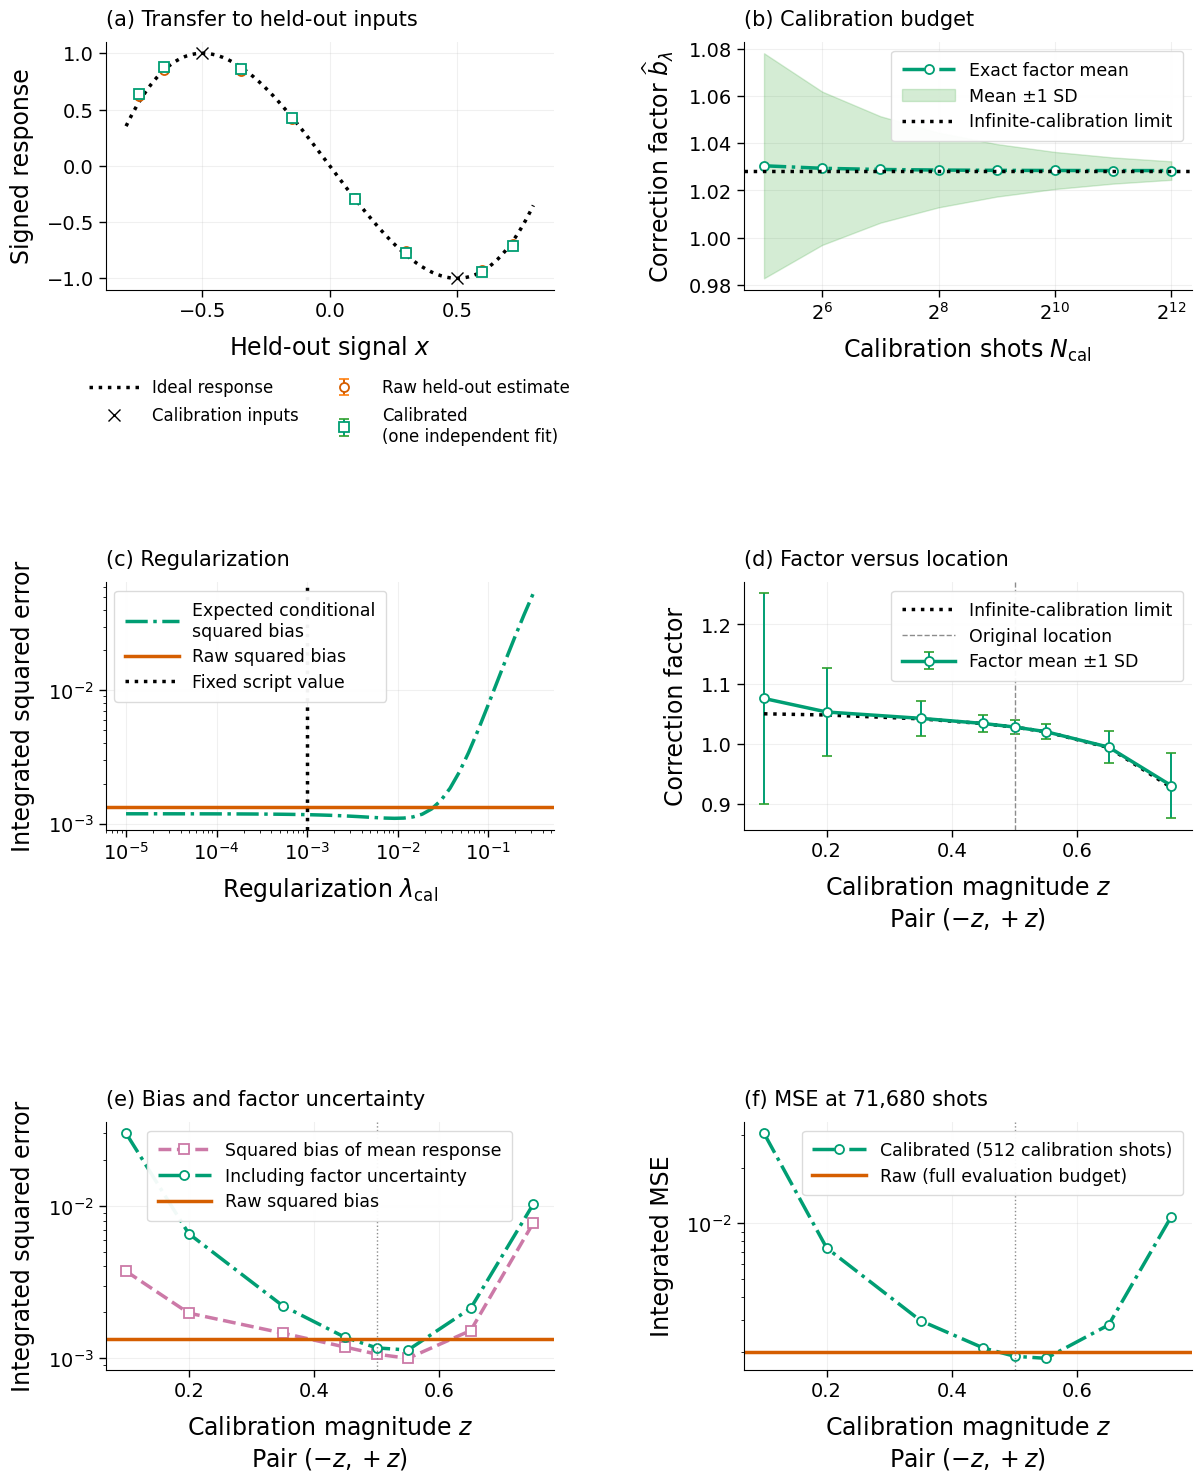

Saved Fig4.png


In [11]:
rng = np.random.default_rng(SEED + 4)
cov = covariance(3, SIGMA, RHO)
g_int = matrix_response(X_INT, CUBIC_PHASES)
mean_int, second_int, response_variance = cubic_moments(X_INT, CUBIC_PHASES, cov)
n_cal = 512
cal_z = 0.5
g_plus = float(matrix_response(cal_z, CUBIC_PHASES)[0])
m_plus = float(exact_mean(cal_z, CUBIC_PHASES, cov)[0])
fitted_b = sample_calibration(CUBIC_PHASES, cov, cal_z, n_cal, LAMBDA_CAL, rng)
fig, axes_grid = plt.subplots(3, 2, figsize=(12.4, 15.2))
axes = axes_grid.ravel()
held_out = np.array([-0.75, -0.65, -0.35, -0.15, 0.10, 0.30, 0.60, 0.72])
sampled, se = estimate_curve(held_out, CUBIC_PHASES, cov, ENSEMBLE_DRAWS, rng, shots=16)
axes[0].plot(X_PLOT, matrix_response(X_PLOT, CUBIC_PHASES), 'k-', label='Ideal response')
axes[0].errorbar(
    held_out, sampled, yerr=se, fmt='o', color='tab:orange',
    capsize=2, label='Raw held-out estimate'
)
axes[0].errorbar(
    held_out, fitted_b * sampled, yerr=abs(fitted_b) * se, fmt='s',
    color='tab:green', capsize=2, label='Corrected, one independent fit'
)
axes[0].plot(
    [-cal_z, cal_z], matrix_response([-cal_z, cal_z], CUBIC_PHASES),
    'kx', ms=8, label='Calibration inputs'
)
axes[0].set_xlabel(r'Held-out signal $x$')
axes[0].set_ylabel('Signed response')
axes[0].legend(loc='lower left')
cal_budgets = np.array([32, 64, 128, 256, 512, 1024, 2048, 4096])
b_means, b_variances = np.array([
    calibration_moments(n, g_plus, m_plus, LAMBDA_CAL)
    for n in cal_budgets
]).T

axes[1].plot(cal_budgets, b_means, 'o-', color='tab:green', label='Exact factor mean')
axes[1].fill_between(
    cal_budgets, b_means - np.sqrt(b_variances), b_means + np.sqrt(b_variances),
    alpha=0.2, color='tab:green', label='Mean +/-1 SD'
)
a_limit = m_plus / g_plus
b_limit = a_limit / (a_limit * a_limit + LAMBDA_CAL)
axes[1].axhline(b_limit, color='k', linestyle=':', label='Infinite-calibration limit')
axes[1].set_xscale('log', base=2)
axes[1].set_xlabel(r'Calibration shots $N_{\mathrm{cal}}$')
axes[1].set_ylabel(r'Correction factor $\widehat b_\lambda$')
axes[1].legend()
raw_bias = float(W_INT @ ((mean_int - g_int)**2))
lambdas = np.logspace(-5, -0.5, 45)
expected_bias = []

for lam in lambdas:
    b_mean, b_var = calibration_moments(n_cal, g_plus, m_plus, lam)
    expected_bias.append(
        float(W_INT @ ((b_mean * mean_int - g_int)**2 + b_var * mean_int**2))
    )

axes[2].semilogx(
    lambdas, expected_bias, color='tab:green',
    label='Expected conditional squared bias')
axes[2].axhline(raw_bias, color='tab:orange', linestyle='--', label='Raw squared bias')
axes[2].axvline(LAMBDA_CAL, color='k', linestyle=':', label='Fixed script value')
axes[2].set_xlabel(r'Regularization $\lambda_{\mathrm{cal}}$')
axes[2].set_ylabel('Integrated squared error')
axes[2].set_yscale('log')
axes[2].legend()
cal_locations = np.array([0.10, 0.20, 0.35, 0.45, 0.50, 0.55, 0.65, 0.75])
location_total_shots = 71680
location_eval_shots = location_total_shots - n_cal
location_shots_per_realization = 8
location_q = len(X_INT)
assert np.all(np.min(np.abs(X_INT[:, None] - cal_locations[None, :]), axis=0) > 1e-12)
assert np.all(np.min(np.abs(X_INT[:, None] + cal_locations[None, :]), axis=0) > 1e-12)
assert n_cal % 2 == 0
assert location_total_shots % (location_q * location_shots_per_realization) == 0
assert location_eval_shots % (location_q * location_shots_per_realization) == 0
location_numerator = (
    1 - mean_int**2
    + (location_shots_per_realization - 1) * response_variance)
location_v_raw = location_numerator / (location_total_shots // location_q)
location_v_eval = location_numerator / (location_eval_shots // location_q)
location_raw_mse = float(W_INT @ ((mean_int - g_int)**2 + location_v_raw))
location_results = []

for z in cal_locations:
    g_z = float(matrix_response(z, CUBIC_PHASES)[0])
    m_z = float(exact_mean(z, CUBIC_PHASES, cov)[0])
    assert abs(g_z) > 1e-8

    a_z = m_z / g_z
    b_infinite = a_z / (a_z * a_z + LAMBDA_CAL)
    b_mean, b_var = calibration_moments(n_cal, g_z, m_z, LAMBDA_CAL)
    b_sd = np.sqrt(b_var)

    mean_squared_bias = float(W_INT @ ((b_mean * mean_int - g_int)**2))
    expected_squared_bias = float(
        W_INT @ ((b_mean * mean_int - g_int)**2 + b_var * mean_int**2))
    calibrated_mse = float(
        W_INT @ (
            (b_mean * mean_int - g_int)**2
            + b_mean * b_mean * location_v_eval
            + b_var * (mean_int**2 + location_v_eval)
        ))
    reduction_percent = 100 * (location_raw_mse - calibrated_mse) / location_raw_mse
    location_results.append([
        z, abs(g_z), m_z, a_z, b_infinite, b_mean, b_sd,
        mean_squared_bias, expected_squared_bias, calibrated_mse, reduction_percent
    ])

location_results = np.array(location_results)
axes[3].errorbar(
    cal_locations, location_results[:, 5], yerr=location_results[:, 6],
    fmt='o-', color='tab:green', capsize=3, label='Factor mean +/-1 SD'
)
axes[3].plot(cal_locations, location_results[:, 4], 'k:', label='Infinite-calibration limit')
axes[3].axvline(
    cal_z, color='0.55', linestyle='--', linewidth=1, label='Original location'
)
axes[3].set_xlabel(r'Calibration magnitude $z$; pair $(-z,+z)$')
axes[3].set_ylabel('Correction factor')
axes[3].legend()

axes[4].semilogy(
    cal_locations, location_results[:, 7], 's--', color='tab:purple',
    label='Squared bias of expected response'
)
axes[4].semilogy(
    cal_locations, location_results[:, 8], 'o-', color='tab:green',
    label='Including calibration uncertainty'
)
axes[4].axhline(raw_bias, color='tab:orange', linestyle='--', label='Raw squared bias')
axes[4].axvline(cal_z, color='0.55', linestyle=':', linewidth=1)
axes[4].set_xlabel(r'Calibration magnitude $z$; pair $(-z,+z)$')
axes[4].set_ylabel('Integrated squared error')
axes[4].legend()
axes[5].semilogy(
    cal_locations, location_results[:, 9], 'o-', color='tab:green',
    label='Calibrated; 512 calibration shots'
)
axes[5].axhline(
    location_raw_mse, color='tab:orange', linestyle='--',
    label='Raw; full budget for evaluation'
)
axes[5].axvline(cal_z, color='0.55', linestyle=':', linewidth=1)
axes[5].set_xlabel(r'Calibration magnitude $z$; pair $(-z,+z)$')
axes[5].set_ylabel('Integrated MSE at 71,680 total shots')
axes[5].legend()

panel_titles = [
    '(a) Transfer at z = 0.5',
    '(b) Calibration budget at z = 0.5',
    '(c) Regularization at z = 0.5',
    '(d) Factor versus calibration location',
    '(e) Error versus calibration location',
    '(f) MSE versus calibration location'
]
for ax, title in zip(axes, panel_titles):
    ax.set_title(title, loc='left', fontsize=11)
print(
    f'Fig4 original fit: b_hat = {fitted_b:.9f}. '
    'Panel (a) bars condition on this fit; '
    'factor bands and bars show SD, not confidence intervals.')
print(
    f'Fig4 location comparison: sigma = {SIGMA}, rho = {RHO}, '
    f'lambda_cal = {LAMBDA_CAL}, calibration shots = {n_cal}, '
    f'total shots = {location_total_shots}, evaluation shots = {location_eval_shots}, '
    f'Q = {location_q}, S_eval = {location_shots_per_realization}.' 
    )
print(
    f'Raw integrated squared bias = {raw_bias:.9e}; '
    f'raw integrated MSE = {location_raw_mse:.9e}. '
    'All errors are unnormalized integrals relative to the ideal cubic polynomial g.')
print(
    'z, |g(z)|, m(z), mean attenuation a_z, infinite-calibration factor, '
    'factor mean, factor SD, squared bias of expected response, '
    'expected conditional squared bias, calibrated MSE, MSE reduction (%)')

for row in location_results:
    print(
        f'{row[0]:.2f}, {row[1]:.6f}, {row[2]:.9f}, {row[3]:.9f}, '
        f'{row[4]:.9f}, {row[5]:.9f}, {row[6]:.9f}, '
        f'{row[7]:.9e}, {row[8]:.9e}, {row[9]:.9e}, {row[10]:.3f}'    )

print(
    'Positive MSE reduction means improvement; negative means increased MSE. '
    'Location-comparison MSEs are model predictions including calibration uncertainty and cost.')
finish_figure(fig, axes, 'Fig4.png')

In [12]:
cov = covariance(3, SIGMA, RHO)
cal_z = 0.5
g_plus = matrix_response(cal_z, CUBIC_PHASES)[0]
m_plus = exact_mean(cal_z, CUBIC_PHASES, cov)[0]

test_nodes, test_weights = np.polynomial.legendre.leggauss(7)
X_TEST, W_TEST = INTERVAL * test_nodes, INTERVAL * test_weights
g_test = matrix_response(X_TEST, CUBIC_PHASES)
m_test, q2_test, v_test = cubic_moments(X_TEST, CUBIC_PHASES, cov)

S_EVAL = 8
Q = len(X_TEST)
BLOCK = Q * S_EVAL
b0 = np.exp(np.trace(cov) / 2)
assert MSE_TRIALS >= 2, 'At least two complete trials are needed for error bars.'
assert np.all(np.abs(X_TEST - cal_z) > 1e-12)
assert np.all(np.abs(X_TEST + cal_z) > 1e-12)

In [13]:
def budget_risks(n_total, n_cal, shots=S_EVAL):
    assert n_total % (Q * shots) == 0
    assert (n_total - n_cal) % (Q * shots) == 0

    n_raw = n_total / Q
    n_eval = (n_total - n_cal) / Q
    numerator = 1 - m_test**2 + (shots - 1) * v_test
    V_raw = numerator / n_raw
    V_eval = numerator / n_eval
    b_mean, b_var = calibration_moments(n_cal, g_plus, m_plus, LAMBDA_CAL)

    raw = W_TEST @ ((m_test - g_test)**2 + V_raw)
    independent = W_TEST @ ((b0 * m_test - g_test)**2 + b0**2 * V_raw)
    calibrated = W_TEST @ (
        (b_mean * m_test - g_test)**2
        + b_mean**2 * V_eval
        + b_var * (m_test**2 + V_eval)
    )
    return np.array([raw, independent, calibrated])

def fig5_trial_losses(n_total, n_cal, trial_index):
    assert 0 < n_cal < n_total and n_cal % 2 == 0
    assert n_total % BLOCK == 0 and (n_total - n_cal) % BLOCK == 0
    trial_seed = np.random.SeedSequence([SEED, 5, int(n_total), int(trial_index)])
    rng = np.random.default_rng(trial_seed)
    raw_estimate, _ = estimate_curve(
        X_TEST, CUBIC_PHASES, cov, n_total // BLOCK, rng, shots=S_EVAL)   
    b_hat = sample_calibration(
        CUBIC_PHASES, cov, cal_z, n_cal, LAMBDA_CAL, rng)
    corrected_data, _ = estimate_curve(
        X_TEST, CUBIC_PHASES, cov, (n_total - n_cal) // BLOCK,
        rng, shots=S_EVAL)
    return np.array([
        W_TEST @ ((raw_estimate - g_test)**2),
        W_TEST @ ((b0 * raw_estimate - g_test)**2),
        W_TEST @ ((b_hat * corrected_data - g_test)**2)
    ])

total_budgets = BLOCK * np.array([40, 80, 160, 320, 640, 1280])
cal_budgets = total_budgets // 5
risks = np.array([
    budget_risks(int(n), int(nc))
    for n, nc in zip(total_budgets, cal_budgets)])
colors = ['tab:orange', 'tab:blue', 'tab:green']
labels = ['Raw, full budget', 'Independent-model factor', 'Calibrated, calibration charged']

Fig5: total shots = 2240, calibration shots = 448, evaluation shots = 1792, trials = 40
  Completed trial 10/40.
  Completed trial 20/40.
  Completed trial 30/40.
  Completed trial 40/40.
Fig5: total shots = 4480, calibration shots = 896, evaluation shots = 3584, trials = 40
  Completed trial 10/40.
  Completed trial 20/40.
  Completed trial 30/40.
  Completed trial 40/40.
Fig5: total shots = 8960, calibration shots = 1792, evaluation shots = 7168, trials = 40
  Completed trial 10/40.
  Completed trial 20/40.
  Completed trial 30/40.
  Completed trial 40/40.
Fig5: total shots = 17920, calibration shots = 3584, evaluation shots = 14336, trials = 40
  Completed trial 10/40.
  Completed trial 20/40.
  Completed trial 30/40.
  Completed trial 40/40.
Fig5: total shots = 35840, calibration shots = 7168, evaluation shots = 28672, trials = 40
  Completed trial 10/40.
  Completed trial 20/40.
  Completed trial 30/40.
  Completed trial 40/40.
Fig5: total shots = 71680, calibration shots = 14336,

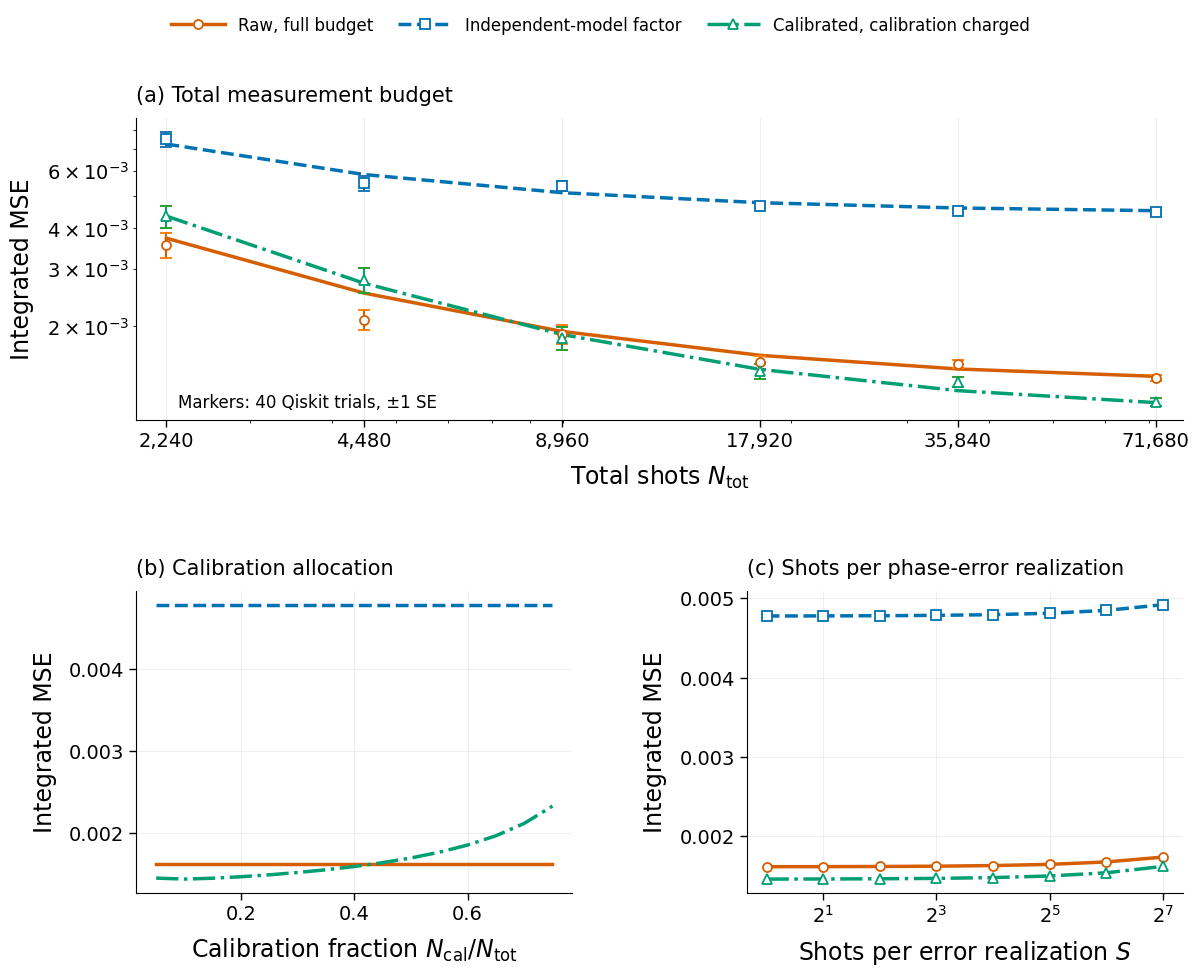

Saved Fig5.png


In [14]:
fig5_losses = np.empty((len(total_budgets), MSE_TRIALS, 3))
fig5_start = time.perf_counter()

for budget_index, (n_total, nc) in enumerate(zip(total_budgets, cal_budgets)):
    n_total, nc = int(n_total), int(nc)
    print(
        f'Fig5: total shots = {n_total}, calibration shots = {nc}, '
        f'evaluation shots = {n_total - nc}, trials = {MSE_TRIALS}',
        flush=True)
    for trial in range(MSE_TRIALS):
        fig5_losses[budget_index, trial] = fig5_trial_losses(n_total, nc, trial)
        if (trial + 1) % 10 == 0 or trial + 1 == MSE_TRIALS:
            print(f'  Completed trial {trial + 1}/{MSE_TRIALS}.', flush=True)

mc_mean = fig5_losses.mean(axis=1)
mc_se = fig5_losses.std(axis=1, ddof=1) / np.sqrt(MSE_TRIALS)
loss_differences = fig5_losses[:, :, 0] - fig5_losses[:, :, 2]
mc_difference = loss_differences.mean(axis=1)
mc_difference_se = loss_differences.std(axis=1, ddof=1) / np.sqrt(MSE_TRIALS)
predicted_reduction = 100 * (risks[:, 0] - risks[:, 2]) / risks[:, 0]
empirical_reduction = 100 * (mc_mean[:, 0] - mc_mean[:, 2]) / mc_mean[:, 0]
fig = plt.figure(figsize=(12.4, 10.0))
grid = fig.add_gridspec(2, 2)
axes = np.array([
    fig.add_subplot(grid[0, :]),
    fig.add_subplot(grid[1, 0]),
    fig.add_subplot(grid[1, 1]),
])

for k, (color, label) in enumerate(zip(colors, labels)):
    axes[0].loglog(total_budgets, risks[:, k], color=color, label=label)
    axes[0].errorbar(
        total_budgets, mc_mean[:, k], yerr=mc_se[:, k], fmt='o',
        color=color, ms=5, capsize=3
    )

axes[0].set_xlim(0.9 * total_budgets[0], 1.1 * total_budgets[-1])
axes[0].set_xlabel(r'Total shots $N_{\rm tot}$')
axes[0].set_ylabel('Integrated MSE')
axes[0].text(
    0.04, 0.04, f'Markers: {MSE_TRIALS} Qiskit trials, +/-1 SE',
    transform=axes[0].transAxes, fontsize=8
)
axes[0].legend()

fixed_total = int(total_budgets[3])
fractions = np.arange(0.05, 0.76, 0.05)
cal_counts = np.rint(fractions * fixed_total / BLOCK).astype(int) * BLOCK
fraction_risks = np.array([
    budget_risks(fixed_total, int(nc)) for nc in cal_counts
])
for k, (color, label) in enumerate(zip(colors, labels)):
    axes[1].plot(cal_counts / fixed_total, fraction_risks[:, k], color=color, label=label)
axes[1].set_xlabel(r'Calibration fraction $N_{\rm cal}/N_{\rm tot}$')
axes[1].set_ylabel('Integrated MSE')
axes[1].legend()
fixed_cal = fixed_total // 5
shot_batches = np.array([1, 2, 4, 8, 16, 32, 64, 128])
batch_risks = np.array([
    budget_risks(fixed_total, fixed_cal, int(s)) for s in shot_batches
])
for k, (color, label) in enumerate(zip(colors, labels)):
    axes[2].plot(shot_batches, batch_risks[:, k], 'o-', color=color, label=label)
axes[2].set_xscale('log', base=2)
axes[2].set_xlabel(r'Shots per error realization $S$')
axes[2].set_ylabel('Integrated MSE')
axes[2].legend()
print('\nFig5 repeated-trial validation:')
print('Total shots | Calibration shots | Method | Predicted MSE | Empirical MSE | SE')
for i, (n_total, nc) in enumerate(zip(total_budgets, cal_budgets)):
    for k, label in enumerate(labels):
        print(
            f'{n_total:6d} | {nc:6d} | {label:31s} | '
            f'{risks[i, k]:.9e} | {mc_mean[i, k]:.9e} | {mc_se[i, k]:.9e}')
    print(
        f'  MSE reduction: predicted = {predicted_reduction[i]:.3f}%, '
        f'empirical = {empirical_reduction[i]:.3f}%.')
    print(
        f'  Empirical raw-minus-calibrated MSE = {mc_difference[i]:.9e} '
        f'+/- {mc_difference_se[i]:.9e} (1 SE).')

print('Positive MSE reduction means improvement; negative means increased MSE.')
print('Error bars show one standard error of the mean across complete independent trials.')
print('Independent-model correction reuses the raw counts and requires no additional shots.')
print(
    f'Total ancilla outcomes across this validation = '
    f'{2 * MSE_TRIALS * int(total_budgets.sum()):,}.')
print(f'Fig5 completed in {(time.perf_counter() - fig5_start) / 60:.2f} minutes.')
finish_figure(fig, axes, 'Fig5.png')

In [15]:
def matrix_signal_gate(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    assert np.max(abs(eigenvalues)) < 1
    square_root = (eigenvectors * np.sqrt(1 - eigenvalues**2)) @ eigenvectors.T
    signal = np.block([[matrix, 1j * square_root], [1j * square_root, matrix]])
    assert np.max(abs(signal.conj().T @ signal - np.eye(4))) < 1e-10
    return UnitaryGate(signal, label='W(A)').control(1)


def matrix_qiskit_response(phases, controlled_signal, state_angle):
    circuit = QuantumCircuit(3)
    circuit.ry(2 * state_angle, 1)
    circuit.h(0)
    circuit.crz(-2 * phases[-1], 0, 2)
    for j in range(len(phases) - 2, -1, -1):
        circuit.append(controlled_signal, [0, 1, 2])
        circuit.crz(-2 * phases[j], 0, 2)
    circuit.h(0)
    state = Statevector.from_instruction(circuit)
    return float(2 * state.probabilities([0])[0] - 1)


def matrix_shared_moments(phases, controlled_signal, state_angle, sigma, points=32):
    nodes, weights = np.polynomial.hermite.hermgauss(points)
    responses = np.array([
        matrix_qiskit_response(
            phases - np.sqrt(2) * sigma * z, controlled_signal, state_angle
        )
        for z in nodes
    ])
    weights = weights / np.sqrt(np.pi)
    return np.array([weights @ responses, weights @ responses**2])


def matrix_noise_moments(case, sigma):
    key = round(float(sigma), 12)
    if key in case['noise_cache']:
        return case['noise_cache'][key]

    phases = case['phases']
    cov = sigma**2 * np.ones((len(phases), len(phases)))
    mean_exact = float(spectral_weights @ exact_mean(eigenvalues, phases, cov))
    previous = matrix_shared_moments(phases, controlled_signal, state_angle, sigma, 32)
    for points in (64, 128, 256):
        current = matrix_shared_moments(
            phases, controlled_signal, state_angle, sigma, points
        )
        quadrature_change = float(np.max(np.abs(current - previous)))
        if quadrature_change < 1e-10:
            break
        previous = current
    else:
        raise RuntimeError(f'Matrix quadrature did not converge at sigma={sigma}.')

    mean, second = map(float, current)
    assert abs(mean - mean_exact) < 1e-9
    assert second - mean**2 > -1e-10
    moments = {
        'sigma': float(sigma), 'mean': mean, 'second': second,
        'variance': max(0.0, second - mean**2),
        'g_cal': float(case['polynomial'](app_cal_z)),
        'm_cal': float(exact_mean(app_cal_z, phases, cov)[0]),
        'b0': float(np.exp(np.trace(cov) / 2)),
        'gh_points': points, 'quadrature_change': quadrature_change,
        'mean_check_error': abs(mean - mean_exact)
    }
    case['noise_cache'][key] = moments
    return moments


def matrix_budget_metrics(case, moments, n_total):
    n_total = int(n_total)
    assert n_total % 5 == 0
    n_cal = n_total // 5
    n_eval = n_total - n_cal
    assert n_cal % 2 == 0 and n_total % app_shots == 0
    assert n_eval % app_shots == 0
    target, ideal = case['target'], case['ideal']
    mean, variance = moments['mean'], moments['variance']
    b_mean, b_var = calibration_moments(
        n_cal, moments['g_cal'], moments['m_cal'], LAMBDA_CAL
    )
    a_limit = moments['m_cal'] / moments['g_cal']
    b_limit = a_limit / (a_limit**2 + LAMBDA_CAL)
    numerator = 1 - mean**2 + (app_shots - 1) * variance
    V_raw, V_eval = numerator / n_total, numerator / n_eval
    ideal_risk = (ideal - target)**2 + (1 - ideal**2) / n_total
    raw_risk = (mean - target)**2 + V_raw
    independent_risk = (
        (moments['b0'] * mean - target)**2 + moments['b0']**2 * V_raw )
    calibrated_risk = (
        (b_mean * mean - target)**2
        + b_mean**2 * V_eval
        + b_var * (mean**2 + V_eval))
    return {
        'n_total': n_total, 'n_cal': n_cal, 'n_eval': n_eval,
        'b_mean': b_mean, 'b_sd': float(np.sqrt(b_var)),
        'corrected_mean': b_mean * mean,
        'raw_bias_squared': (mean - target)**2,
        'calibrated_mean_bias_squared': (b_mean * mean - target)**2,
        'calibration_uncertainty': b_var * mean**2,
        'evaluation_variance_term': (b_mean**2 + b_var) * V_eval,
        'infinite_calibration_bias_squared': (b_limit * mean - target)**2,
        'risks': np.array([ideal_risk, raw_risk, independent_risk, calibrated_risk]),
        'ratio': calibrated_risk / raw_risk,
        'reduction_percent': 100 * (raw_risk - calibrated_risk) / raw_risk
    }


Degree 13: synthesis error 1.22e-15; phases = [ 0.76973093  0.02256911 -0.03603259  0.06174671 -0.10883381  0.19080814
 -0.31903795 -0.31903795  0.19080814 -0.10883381  0.06174671 -0.03603259
  0.02256911  0.76973093]
Degree 13: synthesis error 1.17e-15; phases = [ 0.7796093   0.00970876 -0.01924829  0.0410235  -0.08883307  0.19005955
 -0.3811692  -0.3811692   0.19005955 -0.08883307  0.0410235  -0.01924829
  0.00970876  0.7796093 ]
Degree 13: synthesis error 1.11e-15; phases = [ 0.78332142  0.00412552 -0.01013556  0.02632736 -0.06877922  0.17751156
 -0.42496807 -0.42496807  0.17751156 -0.06877922  0.02632736 -0.01013556
  0.00412552  0.78332142]
Degree 13: synthesis error 9.99e-16; phases = [ 0.78465432  0.00176872 -0.00531261  0.01654371 -0.05156875  0.15918774
 -0.45302194 -0.45302194  0.15918774 -0.05156875  0.01654371 -0.00531261
  0.00176872  0.78465432]
Fig6 scan: sigma = 0.000, converged GH nodes = 64, max moment change = 1.11e-16
Fig6 scan: sigma = 0.025, converged GH nodes = 6

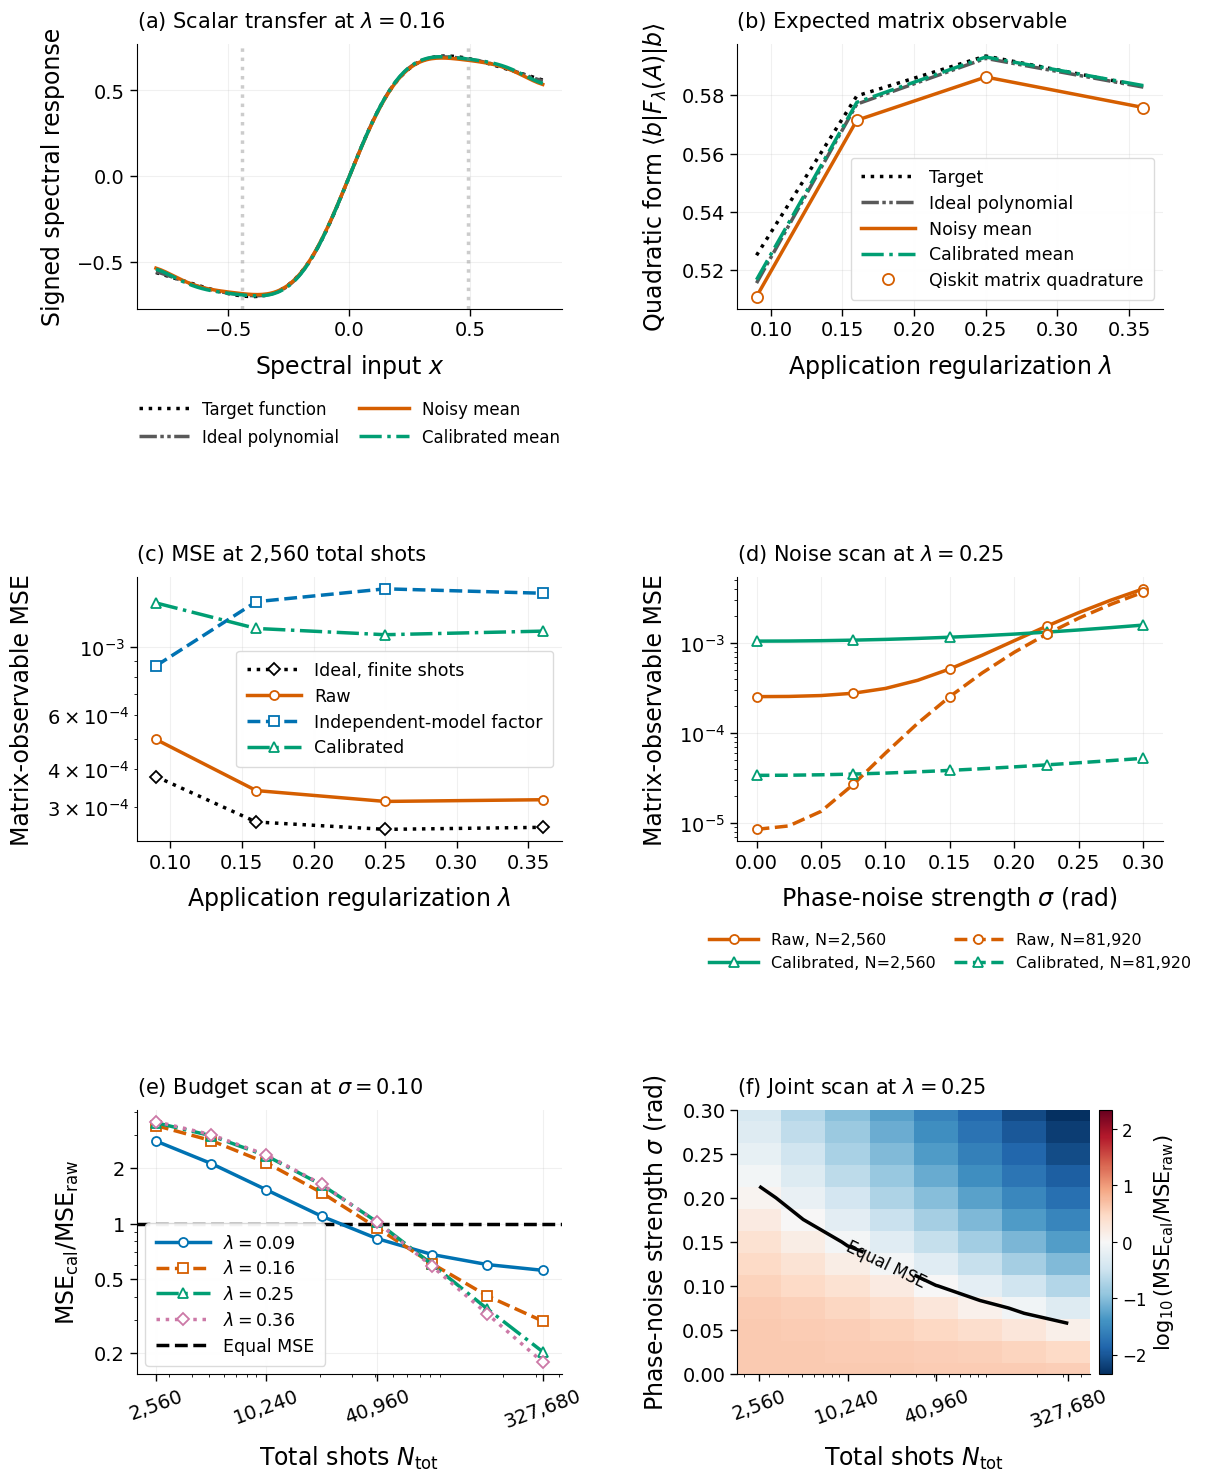

Saved Fig6.png


In [16]:
matrix_A = np.array([[0.15, 0.45], [0.45, -0.10]])
state_angle = 0.37
state_b = np.array([np.cos(state_angle), np.sin(state_angle)])
eigenvalues, eigenvectors = np.linalg.eigh(matrix_A)
spectral_weights = abs(eigenvectors.T @ state_b)**2
controlled_signal = matrix_signal_gate(matrix_A)

degree = 13
app_sigma = 0.10
app_cal_z = 0.5
app_shots = 8
app_total = 2560
app_lambdas = np.array([0.09, 0.16, 0.25, 0.36])
app_reference_lambda = 0.25
app_noise_scan = np.linspace(0.0, 0.30, 13)
app_budget_scan = 2560 * 2**np.arange(8)
app_noise_plot_budgets = (2560, 81920)
app_cases, app_values, app_risks, qiskit_matrix_values = [], [], [], []

for app_lambda in app_lambdas:
    def inverse_function(x):
        return 1.4 * np.sqrt(app_lambda) * x / (x*x + app_lambda)

    coefficients = cheb.chebinterpolate(inverse_function, degree)
    coefficients[::2] = 0
    polynomial = Chebyshev(coefficients)
    phases = synthesize_phases(polynomial)
    case = {
        'lambda': float(app_lambda), 'polynomial': polynomial, 'phases': phases,
        'target': float(spectral_weights @ inverse_function(eigenvalues)),
        'ideal': float(spectral_weights @ polynomial(eigenvalues)),
        'noise_cache': {}
    }
    circuit_ideal = matrix_qiskit_response(phases, controlled_signal, state_angle)
    assert abs(circuit_ideal - case['ideal']) < 1e-9
    moments = matrix_noise_moments(case, app_sigma)
    metrics = matrix_budget_metrics(case, moments, app_total)
    case['base_moments'], case['base_metrics'] = moments, metrics
    app_cases.append(case)
    app_values.append([
        case['target'], case['ideal'], moments['mean'], metrics['corrected_mean']
    ])
    app_risks.append(metrics['risks'])
    qiskit_matrix_values.append(moments['mean'])

app_values, app_risks = np.array(app_values), np.array(app_risks)
reference_case = next(
    case for case in app_cases if np.isclose(case['lambda'], app_reference_lambda)
)

app_budget_results = [
    [matrix_budget_metrics(case, case['base_moments'], n) for n in app_budget_scan]
    for case in app_cases
]

app_scan_results = []
for sigma in app_noise_scan:
    moments = matrix_noise_moments(reference_case, float(sigma))
    app_scan_results.append([
        matrix_budget_metrics(reference_case, moments, n) for n in app_budget_scan
    ])
    print(
        f'Fig6 scan: sigma = {sigma:.3f}, converged GH nodes = {moments["gh_points"]}, '
        f'max moment change = {moments["quadrature_change"]:.2e}', flush=True
    )
app_ratio_grid = np.array([[row['ratio'] for row in rows] for rows in app_scan_results])


fig, axes_grid = plt.subplots(3, 2, figsize=(12.4, 15.2))
axes = axes_grid.ravel()

scalar_case = next(case for case in app_cases if np.isclose(case['lambda'], 0.16))
scalar_lambda = scalar_case['lambda']
scalar_target = 1.4 * np.sqrt(scalar_lambda) * X_PLOT / (X_PLOT**2 + scalar_lambda)
scalar_cov = app_sigma**2 * np.ones((degree + 1, degree + 1))
scalar_mean = exact_mean(X_PLOT, scalar_case['phases'], scalar_cov)
axes[0].plot(X_PLOT, scalar_target, 'k:', label='Target inverse function')
axes[0].plot(X_PLOT, scalar_case['polynomial'](X_PLOT), label='Ideal polynomial')
axes[0].plot(X_PLOT, scalar_mean, color='tab:orange', label='Noisy mean')
axes[0].plot(
    X_PLOT, scalar_case['base_metrics']['b_mean'] * scalar_mean,
    '--', color='tab:green', label='Calibrated mean'
)
for value in eigenvalues:
    axes[0].axvline(value, color='grey', alpha=0.4, linestyle=':')
axes[0].set_xlabel(r'Spectral input $x$')
axes[0].set_ylabel('Signed spectral response')

for k, (color, label) in enumerate(zip(
    ['k', 'tab:blue', 'tab:orange', 'tab:green'],
    ['Target', 'Ideal polynomial', 'Noisy mean', 'Calibrated mean']
)):
    axes[1].plot(app_lambdas, app_values[:, k], '-', color=color, label=label)
axes[1].plot(
    app_lambdas, qiskit_matrix_values, 'o', color='tab:orange',
    ms=4, label='Qiskit matrix quadrature'
)
axes[1].set_xlabel(r'Application regularization $\lambda$')
axes[1].set_ylabel(r'Quadratic form $\langle b|F_\lambda(A)|b\rangle$')

for k, (color, label) in enumerate(zip(
    ['k', 'tab:orange', 'tab:blue', 'tab:green'],
    ['Ideal, finite shots', 'Raw', 'Independent-model factor', 'Calibrated']
)):
    axes[2].semilogy(app_lambdas, app_risks[:, k], 'o-', color=color, label=label)
axes[2].set_xlabel(r'Application regularization $\lambda$')
axes[2].set_ylabel('Matrix-observable MSE')

for n_total, style in zip(app_noise_plot_budgets, ('-', '--')):
    j = int(np.flatnonzero(app_budget_scan == n_total)[0])
    noise_risks = np.array([rows[j]['risks'] for rows in app_scan_results])
    axes[3].semilogy(
        app_noise_scan, noise_risks[:, 1], style, color='tab:orange',
        label=f'Raw, N={n_total:,}'
    )
    axes[3].semilogy(
        app_noise_scan, noise_risks[:, 3], style, color='tab:green',
        label=f'Calibrated, N={n_total:,}'
    )
axes[3].set_xlabel(r'Phase-noise strength $\sigma$ (rad)')
axes[3].set_ylabel('Matrix-observable MSE')

for case, rows in zip(app_cases, app_budget_results):
    axes[4].loglog(
        app_budget_scan, [row['ratio'] for row in rows], 'o-',
        label=rf'$\lambda={case["lambda"]:.2f}$'
    )
axes[4].axhline(1, color='k', linestyle='--', label='Equal MSE')
axes[4].set_xlabel(r'Total shots $N_{\mathrm{tot}}$')
axes[4].set_ylabel(r'$\mathrm{MSE}_{\mathrm{cal}}/\mathrm{MSE}_{\mathrm{raw}}$')


log_ratios = np.log10(app_ratio_grid)
color_limit = max(float(np.max(np.abs(log_ratios))), 1e-6)
budget_edges = np.r_[
    app_budget_scan[0] / np.sqrt(2),
    np.sqrt(app_budget_scan[:-1].astype(float) * app_budget_scan[1:]),
    app_budget_scan[-1] * np.sqrt(2)
]
noise_step = app_noise_scan[1] - app_noise_scan[0]
noise_edges = np.r_[app_noise_scan - noise_step / 2, app_noise_scan[-1] + noise_step / 2]
mesh = axes[5].pcolormesh(
    budget_edges, noise_edges, log_ratios, shading='flat',
    cmap='RdBu_r', vmin=-color_limit, vmax=color_limit
)
axes[5].set_xscale('log')
axes[5].set_ylim(app_noise_scan[0], app_noise_scan[-1])
if log_ratios.min() < 0 < log_ratios.max():
    contour = axes[5].contour(
        app_budget_scan, app_noise_scan, log_ratios, levels=[0], colors='k'
    )
    axes[5].clabel(contour, fmt={0: 'Equal MSE'}, fontsize=8)
colorbar = fig.colorbar(mesh, ax=axes[5], pad=0.02)
colorbar.set_label(r'$\log_{10}(\mathrm{MSE}_{\mathrm{cal}}/\mathrm{MSE}_{\mathrm{raw}})$')
axes[5].set_xlabel(r'Total shots $N_{\mathrm{tot}}$')
axes[5].set_ylabel(r'Phase-noise strength $\sigma$ (rad)')

for ax in axes[4:]:
    ticks = app_budget_scan[[0, 2, 4, 7]]
    ax.set_xticks(ticks, labels=[f'{n:,}' for n in ticks])
    ax.tick_params(axis='x', labelrotation=20)
for ax in axes[:5]:
    ax.legend()
titles = [
    r'(a) Scalar transfer at $\lambda=0.16$',
    '(b) Expected matrix observable',
    '(c) MSE at 2,560 total shots',
    r'(d) Noise scan at $\lambda=0.25$',
    r'(e) Budget scan at $\sigma=0.10$',
    r'(f) Joint scan at $\lambda=0.25$'
]
for ax, title in zip(axes, titles):
    ax.set_title(title, loc='left', fontsize=11)

print('\nFig6: all MSEs are model predictions relative to the target matrix observable.')
print('Calibration uses 20% of every total budget; S_cal=1, S_eval=8, z=+/-0.5.')
print(f'Degree={degree}, lambda_cal={LAMBDA_CAL}, fully shared Gaussian phase noise.')
print('Fig6 original comparison: lambda, target, ideal polynomial, raw mean, calibrated mean')
for case, values, risks_row in zip(app_cases, app_values, app_risks):
    print(f'{case["lambda"]:.2f}', *[f'{value:.9e}' for value in values])
    print('  MSE: ideal, raw, independent model, calibrated:', *[f'{r:.9e}' for r in risks_row])

print('\nFig6 budget table at sigma=0.10:')
print('lambda, total shots, calibration shots, raw MSE, calibrated MSE, reduction (%)')
for case, rows in zip(app_cases, app_budget_results):
    for row in rows:
        print(
            f'{case["lambda"]:.2f}, {row["n_total"]}, {row["n_cal"]}, '
            f'{row["risks"][1]:.9e}, {row["risks"][3]:.9e}, '
            f'{row["reduction_percent"]:.3f}'
        )

print('\nFig6 noise table at lambda=0.25:')
print('sigma, total shots, calibration shots, factor mean, factor SD, raw MSE, cal MSE, gain (%)')
for sigma, rows in zip(app_noise_scan, app_scan_results):
    for n_total in app_noise_plot_budgets:
        j = int(np.flatnonzero(app_budget_scan == n_total)[0])
        row = rows[j]
        print(
            f'{sigma:.3f}, {row["n_total"]}, {row["n_cal"]}, '
            f'{row["b_mean"]:.9f}, {row["b_sd"]:.9f}, '
            f'{row["risks"][1]:.9e}, {row["risks"][3]:.9e}, '
            f'{row["reduction_percent"]:.3f}' )

print('\nFirst TESTED budget with lower calibrated MSE, at each sigma (lambda=0.25):')
for sigma, rows in zip(app_noise_scan, app_scan_results):
    better = [row for row in rows if row['ratio'] < 1]
    if better:
        row = better[0]
        print(
            f'sigma={sigma:.3f}: N={row["n_total"]}, N_cal={row["n_cal"]}, '
            f'raw={row["risks"][1]:.9e}, cal={row["risks"][3]:.9e}, '
            f'reduction={row["reduction_percent"]:.3f}%' )
    else:
        print(f'sigma={sigma:.3f}: no improvement at any tested budget.')

print('These are discrete scan results, not continuous or globally optimal thresholds.')
print('Positive reduction means improvement; the heatmap zero contour is interpolated.')
finish_figure(fig, axes, 'Fig6.png')


Fig7: analytical model predictions; no repeated Qiskit trials.
Cubic response; sigma = 0.2, rho = 0.8, lambda_cal = 0.001.
Evaluation shots per realization = 8; calibration uses one shot.
Allocations use known model moments; additional design shots = 0.
Evaluation interval: [-0.8, 0.8]; nodes = 7.

Panel (a): same total and calibration budgets as Fig5.
Calibration inputs: [-0.5, 0.5]
Total | Cal | Eval | Uniform MSE | Allocated MSE | MSE reduction (%)
  2240 |   448 |  1792 | 4.352622350e-03 | 3.884018311e-03 | 10.766016
  Uniform evaluation counts: [256, 256, 256, 256, 256, 256, 256]
  Allocated evaluation counts: [232, 144, 280, 488, 280, 144, 224]
  Evaluation variance reduction = 14.784787%; factor mean = 1.028533334; factor SD = 0.011919868.
  4480 |   896 |  3584 | 2.705824404e-03 | 2.471463044e-03 | 8.661366
  Uniform evaluation counts: [512, 512, 512, 512, 512, 512, 512]
  Allocated evaluation counts: [456, 288, 560, 968, 568, 288, 456]
  Evaluation variance reduction = 14.791

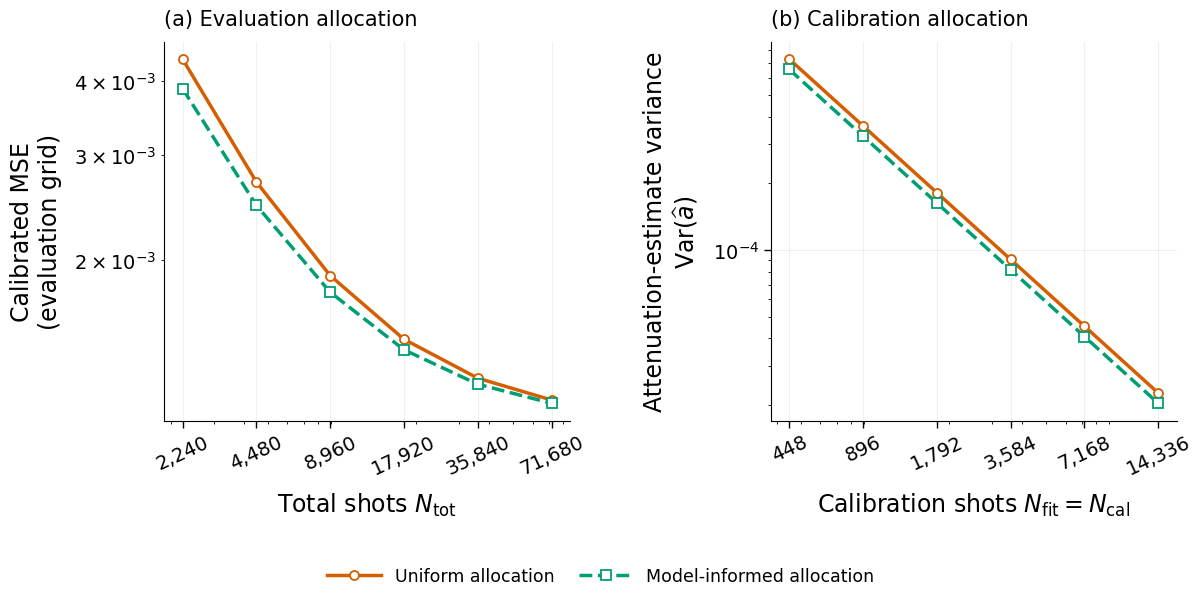

Saved Fig7.png
Fig7 completed in 2.15 seconds.


In [17]:
def integer_allocation(coefficients, total_shots, shots_per_realization):
    coefficients = np.asarray(coefficients, dtype=float)
    total_shots, batch = int(total_shots), int(shots_per_realization)
    assert coefficients.ndim == 1 and np.isfinite(coefficients).all()
    assert np.all(coefficients > 0), 'This experiment has positive coefficients.'
    assert batch >= 1 and total_shots % batch == 0
    counts = np.full(len(coefficients), 2, dtype=int)
    remaining_batches = total_shots // batch - int(counts.sum())
    assert remaining_batches >= 0, 'Budget is too small for the minimum counts.'

    def marginal_decrease(index):
        j = int(counts[index])
        return coefficients[index] / (batch * j * (j + 1))

    heap = [(-marginal_decrease(i), i) for i in range(len(coefficients))]
    heapq.heapify(heap)
    for _ in range(remaining_batches):
        _, i = heapq.heappop(heap)
        counts[i] += 1
        heapq.heappush(heap, (-marginal_decrease(i), i))

    allocation = batch * counts
    assert int(allocation.sum()) == total_shots
    return allocation


def allocation_variance(coefficients, allocation, total_shots, batch):
    coefficients = np.asarray(coefficients, dtype=float)
    allocation = np.asarray(allocation)
    assert int(allocation.sum()) == total_shots
    assert np.all(allocation % batch == 0)
    assert np.all(allocation >= 2 * batch)
    objective = float(np.sum(coefficients / allocation))
    continuous_bound = float(np.sqrt(coefficients).sum()**2 / total_shots)
    assert objective >= continuous_bound - 1e-13
    return objective, continuous_bound

allocation_start = time.perf_counter()
cov = covariance(len(CUBIC_PHASES) - 1, SIGMA, RHO)
g_test = matrix_response(X_TEST, CUBIC_PHASES)
m_test, q2_test, v_test = cubic_moments(X_TEST, CUBIC_PHASES, cov)
g_plus = matrix_response(cal_z, CUBIC_PHASES)[0]
m_plus = exact_mean(cal_z, CUBIC_PHASES, cov)[0]
A_eval = 1 - m_test**2 + (S_EVAL - 1) * v_test
c_eval = W_TEST * A_eval
cal_pair = np.array([-cal_z, cal_z])
g_pair = matrix_response(cal_pair, CUBIC_PHASES)
m_pair = exact_mean(cal_pair, CUBIC_PHASES, cov)
c_pair = g_pair**2 * (1 - m_pair**2) / np.sum(g_pair**2)**2
np.testing.assert_allclose(c_pair[0], c_pair[1], rtol=1e-12)
assert np.all(np.abs(X_TEST[:, None] - cal_pair) > 1e-12)
cal_x = np.array([-cal_z, -0.2, 0.2, cal_z])
eta = np.ones(len(cal_x))
g_cal = matrix_response(cal_x, CUBIC_PHASES)
m_cal = exact_mean(cal_x, CUBIC_PHASES, cov)
A_cal = 1 - m_cal**2
G_cal = float(np.sum(eta * g_cal**2))
c_cal = eta**2 * g_cal**2 * A_cal / G_cal**2
a_mean = float(np.sum(eta * g_cal * m_cal) / G_cal)
assert len(np.unique(cal_x)) == len(cal_x)
assert np.all(np.abs(X_TEST[:, None] - cal_x) > 1e-12)

evaluation_rows, calibration_rows = [], []
for n_total, n_cal in zip(total_budgets, cal_budgets):
    n_total, n_cal = int(n_total), int(n_cal)
    n_eval = n_total - n_cal
    assert n_eval % (len(X_TEST) * S_EVAL) == 0
    uniform_eval = np.full(len(X_TEST), n_eval // len(X_TEST), dtype=int)
    optimal_eval = integer_allocation(c_eval, n_eval, S_EVAL)
    variance_uniform, evaluation_bound = allocation_variance(
        c_eval, uniform_eval, n_eval, S_EVAL)
    variance_optimal, _ = allocation_variance(c_eval, optimal_eval, n_eval, S_EVAL)
    assert variance_optimal <= variance_uniform + 1e-13
    b_mean, b_var = calibration_moments(n_cal, g_plus, m_plus, LAMBDA_CAL)
    fixed_risk = float(
        W_TEST @ ((b_mean * m_test - g_test)**2)
        + b_var * (W_TEST @ m_test**2))
    b_second = b_mean**2 + b_var
    mse_uniform = fixed_risk + b_second * variance_uniform
    mse_optimal = fixed_risk + b_second * variance_optimal
    evaluation_rows.append({
        'total': n_total, 'calibration': n_cal, 'evaluation': n_eval,
        'uniform_counts': uniform_eval, 'optimal_counts': optimal_eval,
        'uniform_mse': mse_uniform, 'optimal_mse': mse_optimal,
        'continuous_mse_bound': fixed_risk + b_second * evaluation_bound,
        'mse_reduction_percent': 100 * (1 - mse_optimal / mse_uniform),
        'variance_reduction_percent': 100 * (1 - variance_optimal / variance_uniform),
        'factor_mean': b_mean, 'factor_sd': np.sqrt(b_var)
    })

    pair_counts = integer_allocation(c_pair, n_cal, 1)
    np.testing.assert_array_equal(pair_counts, [n_cal // 2] * 2)
    assert n_cal % len(cal_x) == 0
    uniform_cal = np.full(len(cal_x), n_cal // len(cal_x), dtype=int)
    optimal_cal = integer_allocation(c_cal, n_cal, 1)
    tau_uniform, calibration_bound = allocation_variance(c_cal, uniform_cal, n_cal, 1)
    tau_optimal, _ = allocation_variance(c_cal, optimal_cal, n_cal, 1)
    assert tau_optimal <= tau_uniform + 1e-13
    calibration_rows.append({
        'calibration': n_cal,
        'uniform_counts': uniform_cal, 'optimal_counts': optimal_cal,
        'uniform_variance': tau_uniform, 'optimal_variance': tau_optimal,
        'continuous_variance_bound': calibration_bound,
        'variance_reduction_percent': 100 * (1 - tau_optimal / tau_uniform)
    })


print('\nFig7: analytical model predictions; no repeated Qiskit trials.')
print(f'Cubic response; sigma = {SIGMA}, rho = {RHO}, lambda_cal = {LAMBDA_CAL}.')
print(f'Evaluation shots per realization = {S_EVAL}; calibration uses one shot.')
print('Allocations use known model moments; additional design shots = 0.')
print(f'Evaluation interval: [-{INTERVAL}, {INTERVAL}]; nodes = {len(X_TEST)}.')
print('\nPanel (a): same total and calibration budgets as Fig5.')
print('Calibration inputs:', cal_pair.tolist())
print('Total | Cal | Eval | Uniform MSE | Allocated MSE | MSE reduction (%)')
for row in evaluation_rows:
    print(
        f'{row["total"]:6d} | {row["calibration"]:5d} | '
        f'{row["evaluation"]:5d} | {row["uniform_mse"]:.9e} | '
        f'{row["optimal_mse"]:.9e} | {row["mse_reduction_percent"]:.6f}')
    print('  Uniform evaluation counts:', row['uniform_counts'].tolist())
    print('  Allocated evaluation counts:', row['optimal_counts'].tolist())
    print(
        f'  Evaluation variance reduction = {row["variance_reduction_percent"]:.6f}%; '
        f'factor mean = {row["factor_mean"]:.9f}; factor SD = {row["factor_sd"]:.9f}.' )
print('Evaluation inputs:', np.array2string(X_TEST, precision=9))
print('\nPanel (b): attenuation-estimate variance for a fixed four-input calibration set.')
print('Calibration inputs:', cal_x.tolist(), '; fitting weights:', eta.tolist())
print(f'Mean fitted attenuation for both allocations = {a_mean:.9f}.')
print('Cal shots | Uniform variance | Allocated variance | Variance reduction (%)')
for row in calibration_rows:
    print(
        f'{row["calibration"]:9d} | {row["uniform_variance"]:.9e} | '
        f'{row["optimal_variance"]:.9e} | '
        f'{row["variance_reduction_percent"]:.6f}' )
    print('  Uniform calibration counts:', row['uniform_counts'].tolist())
    print('  Allocated calibration counts:', row['optimal_counts'].tolist())
print('Panel (b) minimizes Var(a_hat); it does not establish optimal full calibrated MSE.')
print('Both panels keep their input sets and fitting/loss weights fixed between methods.')


fig, axes = plt.subplots(1, 2, figsize=(12.4, 6.3))
for key, color, style, label in (
    ('uniform', 'tab:orange', 'o-', 'Uniform allocation'),
    ('optimal', 'tab:green', 's--', 'Model-informed allocation')):
    axes[0].loglog(
        total_budgets, [row[f'{key}_mse'] for row in evaluation_rows],
        style, color=color, ms=5, label=label)
    axes[1].loglog(
        cal_budgets, [row[f'{key}_variance'] for row in calibration_rows],
        style, color=color, ms=5, label=label   )

axes[0].set_title('(a) Evaluation allocation', loc='left', fontsize=11)
axes[0].set_xlabel(r'Total shots $N_{\mathrm{tot}}$')
axes[0].set_ylabel('Calibrated MSE (evaluation grid)')
axes[1].set_title('(b) Calibration allocation', loc='left', fontsize=11)
axes[1].set_xlabel(r'Calibration shots $N_{\mathrm{fit}}=N_{\mathrm{cal}}$')
axes[1].set_ylabel(r'Attenuation-estimate variance $\mathrm{Var}(\widehat a)$')

for ax, budgets in zip(axes, (total_budgets, cal_budgets)):
    ax.set_xticks(budgets, labels=[f'{n:,}' for n in budgets])
    ax.tick_params(axis='x', labelrotation=25)
    ax.legend(fontsize=9)

finish_figure(fig, axes, 'Fig7.png')
print(f'Fig7 completed in {time.perf_counter() - allocation_start:.2f} seconds.')


Figure 8: exact ensemble bias across nominal phase configurations.
Reused settings: sigma=0.2, rho=0.8, interval=[-0.8, 0.8].
Degrees: [ 3  5  9 13]; sequences per ensemble and degree: 256.
Each free nominal phase is sampled uniformly from [-pi, pi).
The same nominal sequences are used for every correlation value.
Completed degree 3: 512 random sequences and controls.
Degree 5: synthesis error 8.88e-16; phases = [ 0.70797412  0.15643382 -0.57514252 -0.57514252  0.15643382  0.70797412]
Completed degree 5: 512 random sequences and controls.
Degree 9: synthesis error 7.77e-16; phases = [ 0.7751874   0.01939924 -0.0517113   0.1498077  -0.57223629 -0.57223629
  0.1498077  -0.0517113   0.01939924  0.7751874 ]
Completed degree 9: 512 random sequences and controls.
Degree 13: synthesis error 1.22e-15; phases = [ 0.78402937  0.00259309 -0.00682709  0.01868422 -0.05170069  0.14986792
 -0.57222563 -0.57222563  0.14986792 -0.05170069  0.01868422 -0.00682709
  0.00259309  0.78402937]
Completed deg

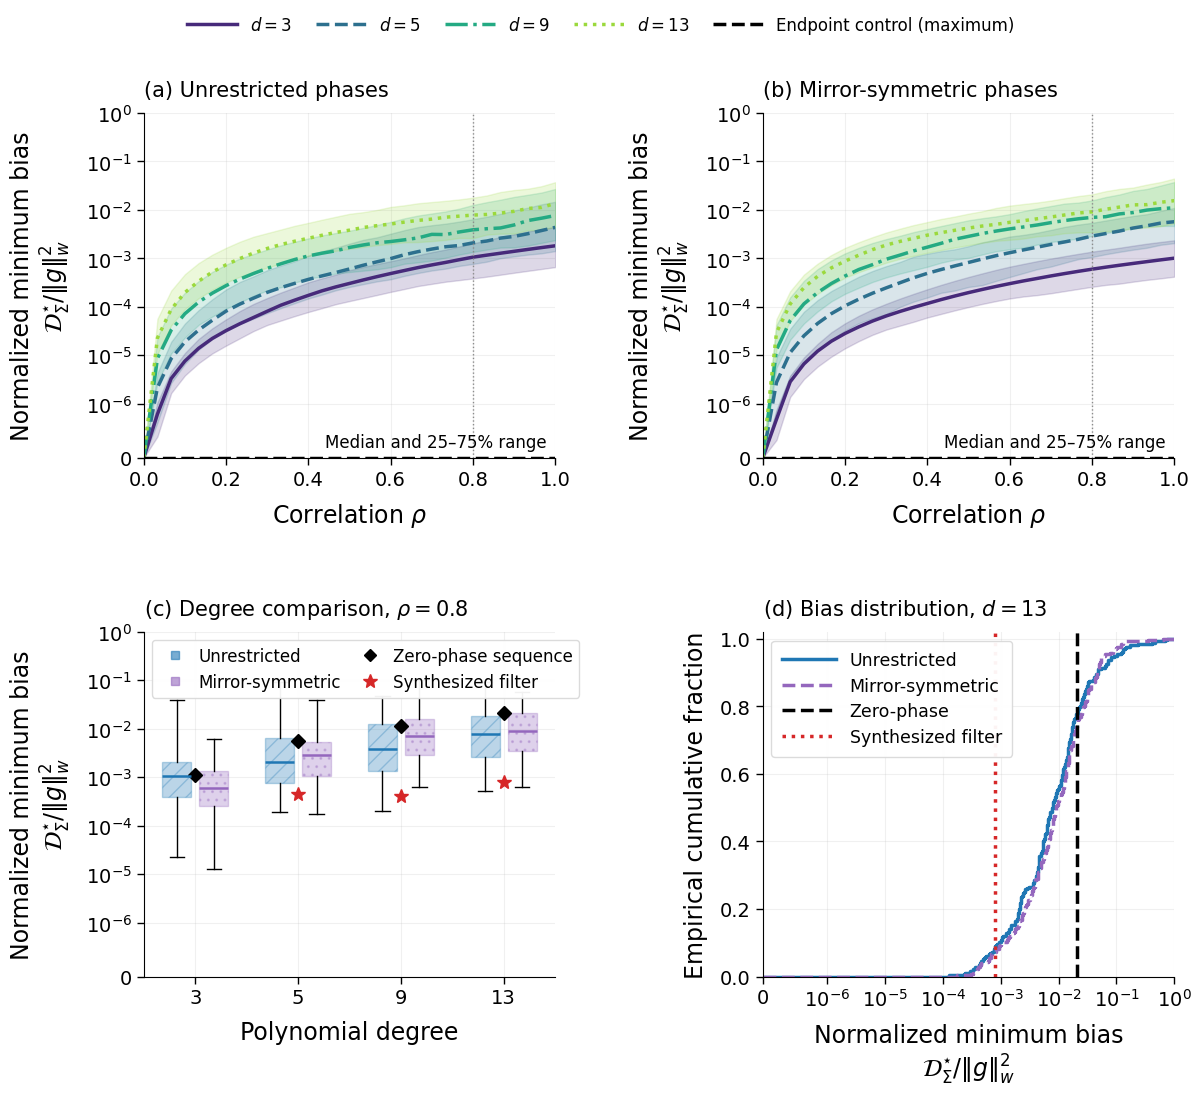

Saved Fig8.png
Boxes: 25--75% range; center line: median; whiskers: 5--95%; outliers omitted.
Figure 8 elapsed time: 9.4 seconds.


In [18]:
sequence_count = 256       
sequence_degrees = np.array(sorted({len(CUBIC_PHASES) - 1, *degrees}), dtype=int)
correlation_values = np.unique(np.r_[0.0, rhos, RHO, 1.0])
ensemble_names = ("Unrestricted", "Mirror-symmetric")
reference_index = int(np.flatnonzero(correlation_values == RHO)[0])
independent_index = int(np.flatnonzero(correlation_values == 0.0)[0])
assert sequence_count > 1
assert SIGMA >= 0 and np.all((correlation_values >= 0) & (correlation_values <= 1))
assert np.all(sequence_degrees >= 2)
assert len(X_INT) >= sequence_degrees.max() + 1
assert np.all(W_INT > 0)


def phase_ensemble_bias(phase_bank, correlation_grid):
    phase_bank = np.asarray(phase_bank, dtype=float)
    order = phase_bank.shape[1] - 1
    signs, groups, _ = path_data(np.zeros(order + 1))
    group_numbers = np.arange(order // 2 + 1)
    masks = [groups == number for number in group_numbers]
    basis = path_basis(X_INT, order, group_numbers)
    path_cosines = np.cos(phase_bank @ signs.T)
    ideal_coefficients = np.column_stack([
        path_cosines[:, mask].sum(axis=1) for mask in masks ])
    ideal = ideal_coefficients @ basis
    energy = np.sum(W_INT * ideal**2, axis=1)
    if np.any(energy <= 0):
        raise ValueError("A zero ideal response cannot be normalized.")
    count = len(correlation_grid)
    damping = np.empty((len(signs), 2 * count))
    for index, correlation in enumerate(correlation_grid):
        exponential_cov = covariance(order, SIGMA, correlation)
        endpoint_cov = covariance(order, SIGMA, 0.0)
        endpoint_cov[0, -1] = endpoint_cov[-1, 0] = correlation * SIGMA**2
        for offset, noise_cov in ((0, exponential_cov), (count, endpoint_cov)):
            quadratic = np.sum((signs @ noise_cov) * signs, axis=1)
            damping[:, offset + index] = np.exp(-quadratic / 2)
    coefficients = np.stack([
        path_cosines[:, mask] @ damping[mask] for mask in masks
    ], axis=-1)
    means = np.einsum("nrk,kx->rnx", coefficients, basis, optimize=True)
    mean_energy = np.sum(W_INT * means**2, axis=-1)
    overlap = np.sum(W_INT * means * ideal[None, :, :], axis=-1)
    factors = np.divide(
        overlap, mean_energy, out=np.zeros_like(overlap), where=mean_energy > 0)
    residuals = factors[:, :, None] * means - ideal[None, :, :]
    minimum_bias = np.sum(W_INT * residuals**2, axis=-1)
    normalized_bias = minimum_bias / energy[None, :]
    assert np.all(normalized_bias >= 0)
    assert normalized_bias.max() <= 1 + 1e-10
    endpoint_factor = np.exp(
        -0.5 * SIGMA**2 * (order + 1 + 2 * correlation_grid) )
    control_error = np.max(np.abs(
        means[count:] - endpoint_factor[:, None, None] * ideal[None, :, :]))
    assert control_error < 1e-10
    assert normalized_bias[count:].max() < 1e-18
    assert normalized_bias[independent_index].max() < 1e-18

    return {
        "ideal": ideal,
        "energy": energy,
        "means": means[:count],
        "factors": factors[:count],
        "minimum_bias": minimum_bias[:count],
        "normalized_bias": normalized_bias[:count],
        "control_normalized_bias": normalized_bias[count:],
        "control_error": float(control_error),
    }


sequence_start = time.perf_counter()
sequence_results, reference_results = {}, {}
sequence_summary, control_summary = [], []
path_check_errors, circuit_check_errors = [], []
probe_inputs = X_INT[[0, len(X_INT) // 3, -1]]

print("\nFigure 8: exact ensemble bias across nominal phase configurations.")
print(f"Reused settings: sigma={SIGMA:g}, rho={RHO:g}, interval=[{-INTERVAL:g}, {INTERVAL:g}].")
print(f"Degrees: {sequence_degrees}; sequences per ensemble and degree: {sequence_count}.")
print("Each free nominal phase is sampled uniformly from [-pi, pi).")
print("The same nominal sequences are used for every correlation value.")

for sequence_degree in sequence_degrees:
    sequence_degree = int(sequence_degree)
    sequence_rng = np.random.default_rng(
        np.random.SeedSequence([SEED, 8, sequence_degree]) )
    unrestricted_phases = sequence_rng.uniform(
        -np.pi, np.pi, size=(sequence_count, sequence_degree + 1) )
    reduced_phases = sequence_rng.uniform(
        -np.pi, np.pi, size=(sequence_count, (sequence_degree + 2) // 2))
    reflected_phases = (
        reduced_phases[:, ::-1] if sequence_degree % 2
        else reduced_phases[:, -2::-1] )
    symmetric_phases = np.concatenate((reduced_phases, reflected_phases), axis=1)
    reference_phases = [np.zeros(sequence_degree + 1)]
    reference_names = ["Zero-phase"]
    if sequence_degree in degrees:
        filter_coefficients = cheb.chebinterpolate(filter_function, sequence_degree)
        filter_coefficients[::2] = 0
        reference_phases.append(synthesize_phases(Chebyshev(filter_coefficients)))
        reference_names.append("Synthesized filter")

    phase_bank = np.vstack((unrestricted_phases, symmetric_phases, reference_phases))
    bank_statistics = phase_ensemble_bias(phase_bank, correlation_values)
    reference_results[sequence_degree] = {}

    for family_index, family_name in enumerate(ensemble_names):
        first = family_index * sequence_count
        selected = slice(first, first + sequence_count)
        normalized = bank_statistics["normalized_bias"][:, selected]
        quantiles = np.percentile(normalized, [5, 25, 50, 75, 95], axis=1)
        sequence_results[sequence_degree, family_name] = {
            "phases": phase_bank[selected].copy(),
            "ideal_energy": bank_statistics["energy"][selected].copy(),
            "factors": bank_statistics["factors"][:, selected].copy(),
            "minimum_bias": bank_statistics["minimum_bias"][:, selected].copy(),
            "normalized_bias": normalized.copy(),
            "quantiles": quantiles,
            "control_maximum": bank_statistics["control_normalized_bias"][:, selected].max(axis=1),
        }
        for correlation_index, correlation in enumerate(correlation_values):
            samples = normalized[correlation_index]
            sequence_summary.append({
                "degree": sequence_degree,
                "ensemble": family_name,
                "rho": float(correlation),
                "count": sequence_count,
                "minimum": float(samples.min()),
                "p05": float(quantiles[0, correlation_index]),
                "p25": float(quantiles[1, correlation_index]),
                "median": float(quantiles[2, correlation_index]),
                "p75": float(quantiles[3, correlation_index]),
                "p95": float(quantiles[4, correlation_index]),
                "maximum": float(samples.max()), })
        sample_phases = phase_bank[first]
        direct_ideal = matrix_response(X_INT, sample_phases)
        direct_mean = exact_mean(
            X_INT, sample_phases, covariance(sequence_degree, SIGMA, RHO))
        path_error = max(
            np.max(np.abs(direct_ideal - bank_statistics["ideal"][first])),
            np.max(np.abs(direct_mean - bank_statistics["means"][reference_index, first])),)
        path_check_errors.append(float(path_error))
        assert path_error < 1e-10
        direct_factor, direct_bias = best_scalar(direct_ideal, direct_mean, W_INT)
        np.testing.assert_allclose(
            bank_statistics["minimum_bias"][reference_index, first],
            direct_bias, rtol=1e-8, atol=1e-16, )
        np.testing.assert_allclose(
            bank_statistics["factors"][reference_index, first],
            direct_factor, rtol=1e-9, atol=1e-11, )
        for probe_x in probe_inputs:
            circuit_error = abs(
                qiskit_response(probe_x, sample_phases)
                - matrix_response(probe_x, sample_phases)[0])
            circuit_check_errors.append(float(circuit_error))
            assert circuit_error < 1e-10

    for reference_offset, reference_name in enumerate(reference_names):
        reference_position = 2 * sequence_count + reference_offset
        reference_results[sequence_degree][reference_name] = {
            "phases": phase_bank[reference_position].copy(),
            "ideal_energy": float(bank_statistics["energy"][reference_position]),
            "normalized_bias": bank_statistics["normalized_bias"][:, reference_position].copy(), }

    control_summary.append({
        "degree": sequence_degree,
        "independent_maximum": float(bank_statistics["normalized_bias"][independent_index].max()),
        "endpoint_maximum": float(bank_statistics["control_normalized_bias"].max()),
        "endpoint_mean_error": bank_statistics["control_error"], })
    print(f"Completed degree {sequence_degree}: {2 * sequence_count} random sequences and controls.", flush=True)

circuit_check_rows = []
check_degree = int(sequence_degrees[-1])
sequence_check_rng = np.random.default_rng(np.random.SeedSequence([SEED, 8, 999]))
print(f"\nQiskit mean checks: degree {check_degree}, {ENSEMBLE_DRAWS} noise draws per input.")
for family_name in ensemble_names:
    check_phases = sequence_results[check_degree, family_name]["phases"][0]
    check_cov = covariance(check_degree, SIGMA, RHO)
    check_exact = exact_mean(probe_inputs, check_phases, check_cov)
    check_mean, check_se = estimate_curve(
        probe_inputs, check_phases, check_cov, ENSEMBLE_DRAWS, sequence_check_rng)
    for probe_x, exact_value, sampled_value, standard_error in zip(
        probe_inputs, check_exact, check_mean, check_se):
        standardized_error = (sampled_value - exact_value) / max(standard_error, 1e-14)
        circuit_check_rows.append({
            "ensemble": family_name, "degree": check_degree, "x": float(probe_x),
            "exact_mean": float(exact_value), "sampled_mean": float(sampled_value),
            "standard_error": float(standard_error), "difference_in_se": float(standardized_error), })
        print(
            f"{family_name:16s} x={probe_x:+.5f}: exact={exact_value:+.7f}, "
            f"Qiskit={sampled_value:+.7f}, SE={standard_error:.3e}, "
            f"difference/SE={standardized_error:+.3f}")


print(f"\nNormalized minimum-bias distributions at rho={RHO:g}:")
print("degree  ensemble          p05          p25          median       p75          p95")
for row in sequence_summary:
    if row["rho"] == RHO:
        print(
            f'{row["degree"]:6d}  {row["ensemble"]:16s}  '
            + "  ".join(f'{row[key]:.9e}' for key in ("p05", "p25", "median", "p75", "p95")) )

print("\nReference sequences at the same sigma and rho:")
for sequence_degree, references in reference_results.items():
    for reference_name, reference_data in references.items():
        reference_bias = reference_data["normalized_bias"][reference_index]
        print(f"d={sequence_degree:2d}, {reference_name:18s}: normalized bias={reference_bias:.9e}")

print("\nRecoverable controls: maximum normalized bias over all sampled phases.")
for row in control_summary:
    print(
        f'd={row["degree"]:2d}: independent={row["independent_maximum"]:.3e}, '
        f'endpoint-only={row["endpoint_maximum"]:.3e}, '
        f'endpoint mean identity error={row["endpoint_mean_error"]:.3e}'
    )
minimum_energy = min(record["ideal_energy"].min() for record in sequence_results.values())
print(f"Smallest sampled ideal-response energy: {minimum_energy:.9e}; no samples were discarded.")
print(f"Maximum existing-helper discrepancy: {max(path_check_errors):.3e}.")
print(f"Maximum noiseless Qiskit discrepancy: {max(circuit_check_errors):.3e}.")
print("All correlation-grid summaries are retained in sequence_summary.")
print("Individual phases, oracle factors, and bias values are retained in sequence_results.")
print("Bands and boxplots show phase-ensemble variation, not sampling error bars.")

fig, axes_grid = plt.subplots(2, 2, figsize=(12.4, 11.2))
axes = axes_grid.ravel()
degree_colors = plt.cm.viridis(np.linspace(0.12, 0.85, len(sequence_degrees)))
family_colors = ("tab:blue", "tab:purple")

for family_index, family_name in enumerate(ensemble_names):
    ax = axes[family_index]
    control_envelope = np.zeros(len(correlation_values))
    for sequence_degree, color in zip(sequence_degrees, degree_colors):
        record = sequence_results[int(sequence_degree), family_name]
        percentiles = record["quantiles"]
        ax.plot(correlation_values, percentiles[2], color=color, label=rf"$d={sequence_degree}$")
        ax.fill_between(correlation_values, percentiles[1], percentiles[3], color=color, alpha=0.18)
        control_envelope = np.maximum(control_envelope, record["control_maximum"])
    ax.plot(correlation_values, control_envelope, "k--", label="Endpoint-only control: maximum")
    ax.axvline(RHO, color="0.55", ls=":", lw=1)
    ax.set_yscale("symlog", linthresh=1e-6)
    ax.set_ylim(0, 1)
    ax.set_xlim(0, 1)
    ax.set_xlabel(r"Correlation $\rho$")
    ax.set_ylabel(r"Normalized minimum bias $\mathcal{D}^{\star}_{\Sigma}/\|g\|_w^2$")
    ax.set_title(f"({chr(97 + family_index)}) {family_name} phases")
    ax.legend(loc="upper left", fontsize=8)
    ax.text(0.98, 0.03, "Median and 25--75% range", transform=ax.transAxes, ha="right", fontsize=8)

positions = np.arange(len(sequence_degrees), dtype=float)
for family_index, (family_name, color) in enumerate(zip(ensemble_names, family_colors)):
    box_data = [
        sequence_results[int(order), family_name]["normalized_bias"][reference_index]
        for order in sequence_degrees]
    boxes = axes[2].boxplot(
        box_data, positions=positions + (-0.18 if family_index == 0 else 0.18),
        widths=0.28, patch_artist=True, showfliers=False, whis=(5, 95), manage_ticks=False, )
    for box in boxes["boxes"]:
        box.set(facecolor=color, edgecolor=color, alpha=0.3)
    for line in boxes["medians"]:
        line.set(color=color, linewidth=1.8)
    axes[2].plot([], [], "s", color=color, alpha=0.6, label=family_name)

for position, sequence_degree in zip(positions, sequence_degrees):
    for reference_name, marker, color in (
        ("Zero-phase", "D", "black"), ("Synthesized filter", "*", "tab:red")):
        if reference_name in reference_results[int(sequence_degree)]:
            value = reference_results[int(sequence_degree)][reference_name]["normalized_bias"][reference_index]
            axes[2].plot(position, value, marker, color=color, ms=7 if marker == "D" else 10)
axes[2].plot([], [], "D", color="black", label="Zero-phase sequence")
axes[2].plot([], [], "*", color="tab:red", ms=10, label="Synthesized filter")
axes[2].set_xticks(positions, labels=[str(order) for order in sequence_degrees])
axes[2].set_xlabel("Polynomial degree")
axes[2].set_ylabel(r"Normalized minimum bias $\mathcal{D}^{\star}_{\Sigma}/\|g\|_w^2$")
axes[2].set_yscale("symlog", linthresh=1e-6)
axes[2].set_ylim(0, 1)
axes[2].set_title(rf"(c) Degree and phase configuration, $\rho={RHO:g}$")
axes[2].legend(loc="upper left", fontsize=8, ncol=2)

for family_name, color in zip(ensemble_names, family_colors):
    values = np.sort(sequence_results[check_degree, family_name]["normalized_bias"][reference_index])
    probabilities = np.arange(1, sequence_count + 1) / sequence_count
    axes[3].step(np.r_[0, values, 1], np.r_[0, probabilities, 1], where="post", color=color, label=family_name)
for reference_name, style, color in (
    ("Zero-phase", "--", "black"), ("Synthesized filter", ":", "tab:red")):
    if reference_name in reference_results[check_degree]:
        value = reference_results[check_degree][reference_name]["normalized_bias"][reference_index]
        axes[3].axvline(value, ls=style, color=color, label=reference_name)
axes[3].set_xscale("symlog", linthresh=1e-6)
axes[3].set_xlim(0, 1)
axes[3].set_ylim(0, 1.02)
axes[3].set_xlabel(r"Normalized minimum bias $\mathcal{D}^{\star}_{\Sigma}/\|g\|_w^2$")
axes[3].set_ylabel("Empirical cumulative fraction")
axes[3].set_title(rf"(d) Bias distribution, $d={check_degree}$, $\rho={RHO:g}$")
axes[3].legend(loc="upper left", fontsize=8)

finish_figure(fig, axes, "Fig8.png")
print("Boxes: 25--75% range; center line: median; whiskers: 5--95%; outliers omitted.")
print(f"Figure 8 elapsed time: {time.perf_counter() - sequence_start:.1f} seconds.")